## DareDevil — Unified Model Comparison Notebook
### Baseline 1 (Stitched) · Baseline 2 (Output Fusion) · Feature Fusion (+ablations) · Feature Fusion + Learned Camera-Identity Shuffle Correction

**What this notebook does, in one pass:**

1. **Baseline 1 — Stitched panorama.** Single shared backbone over a homography-stitched
   panorama, cropped per camera footprint. Ported from `baseline1-3cams-new`.
2. **Baseline 2 — Output Fusion.** Each camera tile goes through its own classification head
   (shared backbone weights), producing independent per-camera logits — these get concatenated
   and passed through a small fusion MLP that produces the final per-camera predictions. This is
   the "fuse decisions, not features" architecture discussed alongside Feature Fusion.
3. **Feature Fusion.** Per-camera shared backbone, features concatenated + 1x1-projected at every
   level before a shared head. Ported from `feature-fusion-real-data`, including the full
   depth/width/activation/head/dropout ablation sweep.
4. **Feature Fusion + Camera-Identity Shuffle Correction.** A small learned classifier predicts
   which physical slot (left/middle/right) each tile actually belongs to — unlike the earlier
   `camera_shuffle_robustness` notebook, which used the *known ground-truth* camera id to
   resort, this version genuinely **infers** identity from the thermal tile itself, then resorts
   before handing off to a Feature-Fusion-style model. This is the realistic version of "what
   happens if the rig gets bumped and a camera's physical slot changes."

**Object classes (new in this notebook):** instead of binary clear/obstructed, every supervised
camera gets a **3-way label**: `0 = no object`, `1 = person`, `2 = other object` — derived from
YOLOv8 detections on the paired RGB frame (COCO class `0` = person; everything else collapses to
"other"). Person takes priority if both a person and another object land in the same camera's
footprint on the same frame.

**Training scope:** only the 3 RGB-supervised cameras (`cam2`, `cam5`, `cam4` — left/middle/right)
are used for training and for the headline evaluation numbers. The 2 side cameras (`cam3`,
`cam6`) are **not** trained on and are **not** part of the main evaluation — but Section 13 swaps
each side camera's tile into the trained models at inference time as a qualitative,
no-ground-truth plausibility check (mirrors `compare_side_predictions_to_naive` from Baseline 1).

**Multi-part data discovery:** capture sessions are auto-discovered by scanning `DATA_ROOT` for
every subfolder matching `part*` (not hardcoded to `part1`/`part2`/`part3` — this will pick up
`part10`, `part11`, etc. with correct *numeric* sort order, not lexicographic).

**Note on execution:** built and syntax-checked end-to-end, following the same structure/coding
conventions as the 3 source notebooks (surgical, verbatim-where-possible porting). It needs your
real Kaggle dataset paths + YOLO weights to actually run — start with `SMOKE_TEST = True`.


## Section 1 — Imports & config

In [1]:
!pip install ultralytics opencv-python-headless --quiet  # uncomment if not already installed

import copy
import json
import random
import re
import time
import warnings
from datetime import datetime
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import f1_score, confusion_matrix

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 25.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 100.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.2

In [2]:
# ---- paths (EDIT THESE) ----
# DATA_ROOT contains part1, part2, part3, ... partN (any number of capture sessions) --
# auto-discovered below by globbing "part*", not hardcoded to 3.
DATA_ROOT = Path("/kaggle/input/datasets/faizmoazam/picturedata/pictureData_3cams/pictureData_3cams")
HOMOGRAPHY_DIR = Path("/kaggle/input/datasets/faizmoazam/thermal-homography-mats/thermal_homography_mats 2/thermal_homography_mats")
RGB_HOMOGRAPHY_DIR = Path("/kaggle/input/datasets/faizmoazam/rgb-homography/rgb homography final/rgb homography final")

YOLO_WEIGHTS = "yolov8x.pt"
MAX_RGB_GAP_MS = 150          # beyond this, treat a "matched" RGB frame as not actually usable
COCO_PERSON_CLASS_ID = 0      # YOLOv8 COCO class id for "person" -- everything else -> "other object"

# ---- rig geometry ----
SENSOR_W, SENSOR_H = 32, 24                 # native per-camera thermal resolution

# Full physical rig (left -> right, as in the rig photo). Only the first 3 (the RGB-supervised,
# RGB-overlapping middle cameras) are trained/evaluated on; the other two are inference-only.
ALL_CAMS_LEFT_TO_RIGHT = [3, 2, 5, 4, 6]
ACTIVE_CAMERAS = [2, 5, 4]                  # left, middle, right -- the 3 cameras used for
                                             # training AND the main evaluation
SIDE_CAMERAS = [3, 6]                       # inference-only, qualitative, no ground truth
CAM_ORDER_LEFT_TO_RIGHT = ACTIVE_CAMERAS    # kept under this name for drop-in compatibility with
                                             # code ported from the 3 source notebooks
DIRECTIONS = ["left", "middle", "right"]    # 1:1 with CAM_ORDER_LEFT_TO_RIGHT
CAM_TO_DIRECTION = dict(zip(CAM_ORDER_LEFT_TO_RIGHT, DIRECTIONS))
DIRECTION_TO_CAM = {v: k for k, v in CAM_TO_DIRECTION.items()}

CLUSTER_BUILD_ORDER = [4, 5, 2]   # BFS root/reference for the panorama -- re-verify against a
                                   # real frame from your 3-cam stitched .npy if this changes
PANORAMA_REFERENCE_CAM = CLUSTER_BUILD_ORDER[0]

# 3-class object taxonomy
CLASS_NAMES = ["no_object", "person", "other_object"]
NUM_CLASSES = len(CLASS_NAMES)

# ---- !!! sensor mirroring fix -- see baseline notebooks for full rationale !!! ----
FLIP_THERMAL_HORIZONTALLY = True
FLIP_CAM_FOOTPRINTS_HORIZONTALLY = False

NUM_CAMS = len(CAM_ORDER_LEFT_TO_RIGHT)

# ---- training config ----
BATCH_SIZE = 64
EPOCHS = 30
LR = 1e-3
SEED = 42
NUM_WORKERS = 2
VAL_FRAC = 0.2
N_SPLIT_BLOCKS = 10

MODEL_DIR = Path("/kaggle/working/saved_models_unified")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# ---- smoke test mode ----
SMOKE_TEST = False
SMOKE_TEST_N_SAMPLES = 60
SMOKE_TEST_EPOCHS = 1
SMOKE_TEST_BATCH_SIZE = 4

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
RANDOM_SEED = SEED


def _part_sort_key(path):
    '''Natural sort: part2 < part10, not lexicographic ('part10' < 'part2' as plain strings).'''
    m = re.search(r"(\d+)$", path.name)
    return int(m.group(1)) if m else 0


def discover_capture_roots(data_root):
    '''Scans data_root for every subfolder named part<N> (any N, any digit count -- part1..part10+),
    sorted numerically. Returns {part_name: path}.'''
    roots = sorted(Path(data_root).glob("part*"), key=_part_sort_key)
    if not roots:
        raise FileNotFoundError(f"No 'part*' folders found under {data_root}")
    return {p.name: p for p in roots}


CAPTURE_ROOTS = discover_capture_roots(DATA_ROOT)
print(f"Discovered {len(CAPTURE_ROOTS)} capture part(s): {list(CAPTURE_ROOTS.keys())}")


def build_capture_parts(capture_roots):
    '''Auto-discovers each part's thermal/rgb/sync subfolders by prefix (thermal-g*, rgb-g*,
    sync-g*), since the exact timestamp suffix differs per recording session.'''

    def _find_one(root, prefix):
        matches = sorted(Path(root).glob(f"{prefix}-g*"))
        if not matches:
            raise FileNotFoundError(f"No '{prefix}-g*' folder found under {root}")
        if len(matches) > 1:
            warnings.warn(f"Multiple '{prefix}-g*' folders under {root}, using {matches[0]}")
        return matches[0]

    parts = {}
    for name, root in capture_roots.items():
        thermal_dir = _find_one(root, "thermal")
        rgb_dir = _find_one(root, "rgb")
        sync_dir = _find_one(root, "sync")
        parts[name] = {
            "thermal_dir": thermal_dir,
            "rgb_dir": rgb_dir,
            "sync_csv": sync_dir / "sync.csv",
        }
    return parts


CAPTURE_PARTS = build_capture_parts(CAPTURE_ROOTS)
for _name, _paths in CAPTURE_PARTS.items():
    print(f"{_name}: thermal={_paths['thermal_dir'].name}  rgb={_paths['rgb_dir'].name}  "
          f"sync_csv exists={_paths['sync_csv'].exists()}")


Discovered 3 capture part(s): ['part1', 'part2', 'part3']
part1: thermal=thermal-g20260616T123146Z  rgb=rgb-g20260616T123146Z  sync_csv exists=True
part2: thermal=thermal-g20260619T081834Z  rgb=rgb-g20260619T081834Z  sync_csv exists=True
part3: thermal=thermal-g20260619T093547Z  rgb=rgb-g20260619T093547Z  sync_csv exists=True


## Section 2 — IO utilities

Ported near-verbatim from the source notebooks / `homography_tool_SURA/core/io_utils.py`.

In [3]:
CAPTURE_RE = re.compile(r"^data_capture_(\d+)_(\d+)_(\d+)\.json$")
CAM_NAME_RE = re.compile(r"cam(\d+)")


def discover_camera_ids(folder):
    folder = Path(folder)
    return sorted({int(m.group(1)) for f in folder.iterdir() if (m := CAPTURE_RE.match(f.name))})


def list_captures(folder, cam_id):
    folder = Path(folder)
    captures = []
    for f in folder.iterdir():
        m = CAPTURE_RE.match(f.name)
        if m and int(m.group(1)) == cam_id:
            captures.append((int(m.group(2)), f))
    captures.sort(key=lambda item: item[0])
    return [path for _seq, path in captures]


def load_capture(path):
    with open(path) as f:
        text = f.read()
    text = re.sub(r"-nan\b", "NaN", text)
    return json.loads(text)


def build_camera_sequence(folder, cam_id):
    '''(frame_index, unix_time_ms, grid) per frame, in capture order. Any 0/NaN pixel is
    filled forward from the previous frame's value at that pixel (sticky fill-forward).
    FLIP_THERMAL_HORIZONTALLY corrects the raw sensor's left-right mirror vs RGB/real-world.'''
    paths = list_captures(folder, cam_id)
    if not paths:
        raise ValueError(f"No captures found for camera {cam_id} in {folder}")
    sequence = []
    buffer = np.zeros(SENSOR_W * SENSOR_H, dtype=np.float64)
    for path in paths:
        data = load_capture(path)
        raw = np.array(data["data"], dtype=np.float64)
        mask = (raw != 0) & ~np.isnan(raw)
        buffer[mask] = raw[mask]
        grid = buffer.copy().reshape(SENSOR_H, SENSOR_W)
        if FLIP_THERMAL_HORIZONTALLY:
            grid = np.ascontiguousarray(grid[:, ::-1])
        sequence.append((data["frame_index"], data["unix_time_ms"], grid))
    return sequence


def compute_normalization_range(grids, low_pct=1, high_pct=99):
    flat = np.concatenate([g.ravel() for g in grids])
    return np.percentile(flat, low_pct), np.percentile(flat, high_pct)


def temps_to_uint8(grid, vmin, vmax):
    clipped = np.clip(grid, vmin, vmax)
    return ((clipped - vmin) / max(vmax - vmin, 1e-6) * 255).astype(np.uint8)


def load_homography_json(path):
    with open(path) as f:
        return json.load(f)


def discover_homography_files(root):
    root = Path(root)
    entries = []
    for path in sorted(root.rglob("*_homography.json")):
        data = load_homography_json(path)
        a_m, b_m = CAM_NAME_RE.match(data.get("cam_a", "")), CAM_NAME_RE.match(data.get("cam_b", ""))
        if not (a_m and b_m):
            continue
        entries.append({"cam_a": int(a_m.group(1)), "cam_b": int(b_m.group(1)),
                         "H": np.array(data["H"], dtype=np.float64)})
    return entries


def load_sync_table(csv_path):
    return pd.read_csv(csv_path).to_dict("records")


def rgb_gap_ok(row, max_gap_ms=MAX_RGB_GAP_MS):
    gap = row.get("rgb_gap_ms", "-1")
    files = row.get("rgb_files", "")
    if not files:
        return False
    try:
        return 0 <= float(gap) <= max_gap_ms
    except ValueError:
        return False


def load_all_sync_rows(capture_parts=None, seed=RANDOM_SEED):
    '''Combines every discovered part's sync.csv -- (part, anchor_index) is the unique sample
    identity (anchor_index alone restarts at 0 for every part).'''
    capture_parts = capture_parts or CAPTURE_PARTS
    all_rows = []
    for part_name, paths in capture_parts.items():
        rows = load_sync_table(paths["sync_csv"])
        for i, row in enumerate(rows):
            row["_part"] = part_name
            row.setdefault("anchor_index", i)
        all_rows.extend(rows)
    random.Random(seed).shuffle(all_rows)
    print(f"total: {len(all_rows)} rows across {len(capture_parts)} part(s)")
    return all_rows


## Section 3 — Panorama geometry (label-projection only)

Stitching geometry is only used here to define each camera's real footprint polygon, so
YOLO-on-RGB detections can be tested for overlap against the *actual* camera field of view
rather than a guessed equal-width split. Baseline 1 additionally uses this geometry to build the
literal stitched input image; Baselines 2-4 only need `CAM_FOOTPRINTS`/`CAM_TRANSFORMS` for
labeling, not for the model's input tensor.

In [4]:
def _transform_corners(width, height, T):
    corners = np.array([[0, 0], [width - 1, 0], [width - 1, height - 1], [0, height - 1]], dtype=np.float64)
    corners_h = np.hstack([corners, np.ones((4, 1))])
    transformed = (T @ corners_h.T).T
    return transformed[:, :2] / transformed[:, 2:3]


def compute_canvas_bounds(frame_shapes, transforms):
    all_points = np.vstack([_transform_corners(w, h, T) for (h, w), T in zip(frame_shapes, transforms)])
    min_x, min_y = np.floor(all_points.min(axis=0)).astype(int)
    max_x, max_y = np.ceil(all_points.max(axis=0)).astype(int)
    return min_x, min_y, max_x, max_y


def build_clusters(homography_entries, cam_ids):
    graph = {cam: [] for cam in cam_ids}
    for entry in homography_entries:
        a, b, H = entry["cam_a"], entry["cam_b"], entry["H"]
        if a not in graph or b not in graph:
            continue
        graph[a].append((b, np.linalg.inv(H)))
        graph[b].append((a, H))

    visited, clusters = set(), []
    for root_cam in cam_ids:
        if root_cam in visited:
            continue
        visited.add(root_cam)
        cams, transforms = [root_cam], [np.eye(3)]
        transform_to_root = {root_cam: np.eye(3)}
        queue = [root_cam]
        while queue:
            current = queue.pop(0)
            for neighbor, T_neighbor_to_current in graph[current]:
                if neighbor in visited:
                    continue
                visited.add(neighbor)
                transform_to_root[neighbor] = transform_to_root[current] @ T_neighbor_to_current
                cams.append(neighbor)
                transforms.append(transform_to_root[neighbor])
                queue.append(neighbor)
        clusters.append({"cams": cams, "transforms": transforms})
    return clusters


def warp_image(img, H, output_size):
    return cv2.warpPerspective(img, H, output_size, flags=cv2.INTER_NEAREST,
                                borderMode=cv2.BORDER_CONSTANT, borderValue=0)


def stitch_frames(frames, transforms):
    shapes = [f.shape for f in frames]
    min_x, min_y, max_x, max_y = compute_canvas_bounds(shapes, transforms)
    canvas_w, canvas_h = max_x - min_x, max_y - min_y
    translation = np.array([[1, 0, -min_x], [0, 1, -min_y], [0, 0, 1]], dtype=np.float64)
    canvas = np.zeros((canvas_h, canvas_w), dtype=frames[0].dtype)
    for frame, T in zip(frames, transforms):
        warped = warp_image(frame, translation @ T, (canvas_w, canvas_h))
        mask = warped > 0
        canvas[mask] = warped[mask]
    return canvas


# Build geometry over ONLY the 3 active cameras (cam2/cam5/cam4) -- this is the cluster that's
# actually guaranteed to be fully connected by HOMOGRAPHY_DIR's thermal-thermal pairs (cam4<->cam5,
# cam5<->cam2). Side cameras (cam3/cam6) are NOT included here: their homography edges to this
# cluster aren't guaranteed to exist (see baseline1's open-item notes -- "any leftover cam3/cam6
# homography files are harmless and ignored"), and nothing downstream actually needs side-camera
# footprint polygons -- Section 16's side-camera swap-in check works directly on raw tiles, never
# on CAM_FOOTPRINTS. Earlier attempt to also build side-camera footprints here caused a KeyError
# when cam2 ended up isolated in its own disconnected cluster -- this is the fix.
homography_entries = discover_homography_files(HOMOGRAPHY_DIR)
clusters = build_clusters(homography_entries, CLUSTER_BUILD_ORDER)
main_cluster = next((c for c in clusters if len(c["cams"]) == NUM_CAMS and set(c["cams"]) == set(ACTIVE_CAMERAS)), None)
if main_cluster is None:
    raise RuntimeError(
        f"Could not find a single connected cluster containing exactly {ACTIVE_CAMERAS} in "
        f"HOMOGRAPHY_DIR's thermal-thermal pairs. Clusters found: {[c['cams'] for c in clusters]} "
        "-- check that cam4<->cam5 and cam5<->cam2 homography files are present."
    )
print("cluster cams (BFS order from reference):", main_cluster["cams"])

PANORAMA_MIN_X, PANORAMA_MIN_Y, PANORAMA_MAX_X, PANORAMA_MAX_Y = compute_canvas_bounds(
    [(SENSOR_H, SENSOR_W)] * len(main_cluster["cams"]), main_cluster["transforms"]
)
PANORAMA_W = PANORAMA_MAX_X - PANORAMA_MIN_X
PANORAMA_H = PANORAMA_MAX_Y - PANORAMA_MIN_Y
print(f"panorama canvas: {PANORAMA_H} x {PANORAMA_W}  -- verify visually against a real frame")

PANORAMA_TRANSLATION = np.array([
    [1, 0, -PANORAMA_MIN_X], [0, 1, -PANORAMA_MIN_Y], [0, 0, 1],
], dtype=np.float64)

CAM_FOOTPRINTS = {}
CAM_TRANSFORMS = {}
for cam_id, T in zip(main_cluster["cams"], main_cluster["transforms"]):
    CAM_TRANSFORMS[cam_id] = T
    full_T = PANORAMA_TRANSLATION @ T
    corners = _transform_corners(SENSOR_W, SENSOR_H, full_T)
    x1, y1 = corners[:, 0].min(), corners[:, 1].min()
    x2, y2 = corners[:, 0].max(), corners[:, 1].max()
    CAM_FOOTPRINTS[cam_id] = {"polygon": corners, "bbox": (x1, y1, x2, y2)}
    tag = "ACTIVE" if cam_id in ACTIVE_CAMERAS else "side (inference-only)"
    print(f"cam{cam_id} [{tag}]: bbox = ({x1:.1f}, {y1:.1f}, {x2:.1f}, {y2:.1f})")


cluster cams (BFS order from reference): [4, 5, 2]
panorama canvas: 25 x 79  -- verify visually against a real frame
cam4 [ACTIVE]: bbox = (48.0, 1.0, 79.0, 24.0)
cam5 [ACTIVE]: bbox = (24.1, 1.1, 55.1, 24.0)
cam2 [ACTIVE]: bbox = (0.5, 0.1, 29.4, 22.8)


## Section 4 — Loading panoramas (Baseline 1) and raw per-camera tiles (Baselines 2-4)

In [5]:
_RAW_SEQUENCES = {}  # part_name -> {cam_id: [grid, grid, ...]}, cached on first access


def _get_raw_sequences(part):
    if part not in _RAW_SEQUENCES:
        thermal_dir = CAPTURE_PARTS[part]["thermal_dir"]
        cams_needed = list(set(ALL_CAMS_LEFT_TO_RIGHT))
        _RAW_SEQUENCES[part] = {
            cam_id: [grid for _idx, _ts, grid in build_camera_sequence(thermal_dir, cam_id)]
            for cam_id in cams_needed
        }
    return _RAW_SEQUENCES[part]


def load_camera_tiles(part, anchor_index, cam_order=None):
    '''Raw (SENSOR_H, SENSOR_W) grids for this (part, anchor_index), one per camera, in
    cam_order (defaults to the 3 ACTIVE_CAMERAS).'''
    cam_order = cam_order or CAM_ORDER_LEFT_TO_RIGHT
    sequences = _get_raw_sequences(part)
    return [sequences[cam_id][anchor_index].astype(np.float32) for cam_id in cam_order]


def build_input_tensor(tiles):
    '''tiles: list of NUM_CAMS (H, W) arrays -> [NUM_CAMS, 1, H, W] -- used by Baselines 2-4
    (unstitched per-camera input).'''
    return np.stack([t[None, :, :] for t in tiles], axis=0)


def pad_or_crop_to_canvas(panorama, target_h=None, target_w=None):
    target_h = target_h or PANORAMA_H
    target_w = target_w or PANORAMA_W
    h, w = panorama.shape
    out = np.zeros((target_h, target_w), dtype=panorama.dtype)
    copy_h, copy_w = min(h, target_h), min(w, target_w)
    out[:copy_h, :copy_w] = panorama[:copy_h, :copy_w]
    return out


def load_panorama(part, anchor_index, cam_order=None):
    '''Stitched panorama -- used only by Baseline 1. Always recomputed from raw tiles +
    homographies (no pre-saved .npy dependency), consistent with FLIP_THERMAL_HORIZONTALLY.'''
    cam_order = cam_order or CAM_ORDER_LEFT_TO_RIGHT
    sequences = _get_raw_sequences(part)
    frames = [sequences[c][anchor_index] for c in main_cluster["cams"] if c in cam_order or c in ALL_CAMS_LEFT_TO_RIGHT]
    # stitch over exactly the cams in main_cluster (so transforms line up); cam_order restriction
    # is applied later via CAM_FOOTPRINTS bbox crops, not by omitting cameras from the canvas.
    frames_all = [sequences[c][anchor_index] for c in main_cluster["cams"]]
    transforms_all = main_cluster["transforms"]
    panorama = stitch_frames(frames_all, [PANORAMA_TRANSLATION @ T for T in transforms_all])
    return pad_or_crop_to_canvas(panorama)


def build_stitched_input_tensor(panorama):
    '''[2, H, W]: temperature channel + binary validity mask channel (1 = real pixel, 0 = black
    padding) -- used only by Baseline 1 (stitched).'''
    mask = (panorama > 0).astype(np.float32)
    return np.stack([panorama.astype(np.float32), mask], axis=0)


## Section 5 — Label generation: 3-class (no_object / person / other_object)

Same partial-supervision discipline as the source notebooks (`CAM_IDS_WITH_RGB_OVERLAP`,
`mask_vec` hard-zeros any camera RGB structurally doesn't overlap), but the label itself is now
an **integer class** per camera instead of a binary bit:

- `0` = no object detected in that camera's footprint
- `1` = **person** (YOLO COCO class `0`) detected in that camera's footprint
- `2` = some other object class detected (and no person)

**Priority rule:** if both a person and another object land in the same camera's footprint on
the same frame, the label is `1` (person) — person presence is the more navigation-relevant
signal (a person can move; furniture won't).

In [6]:
def discover_rgb_homographies(root):
    root = Path(root)
    calibrations = {}
    for path in sorted(root.rglob("rgb*_homography.json")):
        data = load_homography_json(path)
        if data["cam_a"] != "rgb":
            continue
        cam_id = int(CAM_NAME_RE.match(data["cam_b"]).group(1))
        quad_a = np.array(data["quad_a"], dtype=np.float64)
        calibrations[cam_id] = {
            "H": np.array(data["H"], dtype=np.float64),
            "quad_a": quad_a,
            "quad_a_centroid": quad_a.mean(axis=0),
        }
    return calibrations


RGB_CALIBRATIONS = discover_rgb_homographies(RGB_HOMOGRAPHY_DIR)
CAM_IDS_WITH_RGB_OVERLAP = set(RGB_CALIBRATIONS.keys()) & set(ALL_CAMS_LEFT_TO_RIGHT)
print("cameras with RGB overlap (calibrated):", sorted(CAM_IDS_WITH_RGB_OVERLAP))
print("ACTIVE cameras with NO RGB overlap (would be permanently unsupervised, shouldn't happen):",
      sorted(set(ACTIVE_CAMERAS) - CAM_IDS_WITH_RGB_OVERLAP))

USE_REAL_LABELS = len(RGB_CALIBRATIONS) > 0
if not USE_REAL_LABELS:
    warnings.warn(
        "No rgb*_homography.json files found -- falling back to NAIVE intensity-threshold "
        "pseudo-labels (2-class: object/no-object, since 'person vs other' can't be told apart "
        "without RGB+YOLO). Treat results from this run as a pipeline smoke test only."
    )

if USE_REAL_LABELS:
    from ultralytics import YOLO
    from matplotlib.path import Path as MplPath

    _yolo_model = YOLO(YOLO_WEIGHTS)
    PANORAMA_T_FOR_CAM = {cam_id: PANORAMA_TRANSLATION @ T for cam_id, T in CAM_TRANSFORMS.items()}

    def _nearest_calibration(box_xyxy):
        x1, y1, x2, y2 = box_xyxy
        box_center = np.array([(x1 + x2) / 2, (y1 + y2) / 2])
        best_cam, best_dist = None, np.inf
        for cam_id, calib in RGB_CALIBRATIONS.items():
            dist = np.linalg.norm(box_center - calib["quad_a_centroid"])
            if dist < best_dist:
                best_cam, best_dist = cam_id, dist
        return best_cam

    def _project_rgb_box_to_panorama(box_xyxy, via_cam_id):
        x1, y1, x2, y2 = box_xyxy
        corners = np.array([[x1, y1], [x2, y1], [x2, y2], [x1, y2]], dtype=np.float64)
        corners_h = np.hstack([corners, np.ones((4, 1))])
        combined = PANORAMA_T_FOR_CAM[via_cam_id] @ RGB_CALIBRATIONS[via_cam_id]["H"]
        out = (combined @ corners_h.T).T
        return out[:, :2] / out[:, 2:3]

    def generate_real_labels(rgb_path, cam_ids=None):
        '''Returns {cam_id: (class_id, list_of_boxes_for_viz)} for every cam_id in cam_ids
        (defaults to every RGB-overlapping camera). class_id in {0, 1, 2}.'''
        cam_ids = cam_ids or sorted(CAM_IDS_WITH_RGB_OVERLAP)
        img = cv2.imread(str(rgb_path))
        if img is None:
            return None
        results = _yolo_model(img, verbose=False)[0]
        has_person = {cam_id: False for cam_id in cam_ids}
        has_other = {cam_id: False for cam_id in cam_ids}
        boxes_by_cam = {cam_id: [] for cam_id in cam_ids}
        for box, cls in zip(results.boxes.xyxy.cpu().numpy(), results.boxes.cls.cpu().numpy()):
            via_cam = _nearest_calibration(box)
            panorama_corners = _project_rgb_box_to_panorama(box, via_cam)
            cx, cy = panorama_corners[:, 0].mean(), panorama_corners[:, 1].mean()
            is_person = int(cls) == COCO_PERSON_CLASS_ID
            for cam_id in cam_ids:
                poly_path = MplPath(CAM_FOOTPRINTS[cam_id]["polygon"])
                pts_to_check = list(map(tuple, panorama_corners)) + [(cx, cy)]
                if any(poly_path.contains_point(p) for p in pts_to_check):
                    if is_person:
                        has_person[cam_id] = True
                    else:
                        has_other[cam_id] = True
                    boxes_by_cam[cam_id].append((box, int(cls), is_person))
        labels = {}
        for cam_id in cam_ids:
            if has_person[cam_id]:
                labels[cam_id] = 1
            elif has_other[cam_id]:
                labels[cam_id] = 2
            else:
                labels[cam_id] = 0
        return labels, boxes_by_cam


def generate_naive_labels(tiles_by_cam, threshold_std=1.5):
    '''Fallback-mode placeholder, UNSTITCHED: 2-class only (no_object=0 vs other_object=2 --
    'person' can't be distinguished without RGB+YOLO, so naive mode never emits class 1).'''
    return {cam_id: (2 if (grid.size > 0 and grid.std() > threshold_std) else 0)
            for cam_id, grid in tiles_by_cam.items()}


_label_cache = {}        # (part, anchor_index) -> (class_vec[int], mask_vec[float])
_label_boxes_cache = {}  # (part, anchor_index) -> boxes_by_cam, kept ONLY for the preview cells


def _sample_key(row):
    return (row["_part"], int(row["anchor_index"]))


def get_or_compute_label(row, tiles=None, keep_boxes=False):
    key = _sample_key(row)
    if key in _label_cache:
        return _label_cache[key]

    part, anchor_index = key
    if USE_REAL_LABELS:
        has_rgb = rgb_gap_ok(row)
        result = generate_real_labels(CAPTURE_PARTS[part]["rgb_dir"] / row["rgb_files"]) if has_rgb else None
        class_vec = np.zeros(NUM_CAMS, dtype=np.int64)
        mask_vec = np.zeros(NUM_CAMS, dtype=np.float32)
        boxes_by_cam = {}
        if result is not None:
            rgb_labels, boxes_by_cam = result
            for i, cam_id in enumerate(CAM_ORDER_LEFT_TO_RIGHT):
                if cam_id not in CAM_IDS_WITH_RGB_OVERLAP:
                    continue
                class_vec[i] = rgb_labels[cam_id]
                mask_vec[i] = 1.0
        if keep_boxes:
            _label_boxes_cache[key] = boxes_by_cam
    else:
        if tiles is None:
            tiles = load_camera_tiles(part, anchor_index)
        tiles_by_cam = dict(zip(CAM_ORDER_LEFT_TO_RIGHT, tiles))
        naive_labels = generate_naive_labels(tiles_by_cam)
        class_vec = np.array([naive_labels[c] for c in CAM_ORDER_LEFT_TO_RIGHT], dtype=np.int64)
        mask_vec = np.ones(NUM_CAMS, dtype=np.float32)

    _label_cache[key] = (class_vec, mask_vec)
    return class_vec, mask_vec


def precompute_labels(sync_rows_to_cache):
    '''Computes (and caches) labels up front, sequentially, in the main process -- required so
    DataLoader(num_workers>0) workers never run YOLO/CUDA inline (forked CUDA crash).'''
    n_new = sum(1 for r in sync_rows_to_cache if _sample_key(r) not in _label_cache)
    if n_new == 0:
        return
    print(f"Precomputing labels for {n_new} sample(s)"
          f"{' (running YOLO once per frame)' if USE_REAL_LABELS else ' (naive thresholds)'}...")
    for row in sync_rows_to_cache:
        if _sample_key(row) in _label_cache:
            continue
        get_or_compute_label(row)
    print("done.")


cameras with RGB overlap (calibrated): [2, 4, 5]
ACTIVE cameras with NO RGB overlap (would be permanently unsupervised, shouldn't happen): []
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


## Section 6 — Visualization: example input + label overlay

A handful of random samples: the RGB frame with raw YOLO boxes drawn (color-coded person vs
other object), the resulting per-camera class label, and the raw thermal tile that the model
actually receives for each of the 3 active cameras. This is the single most useful sanity check
before trusting anything downstream -- confirm the projected label matches what's visible in the
photo.

total: 3433 rows across 3 part(s)


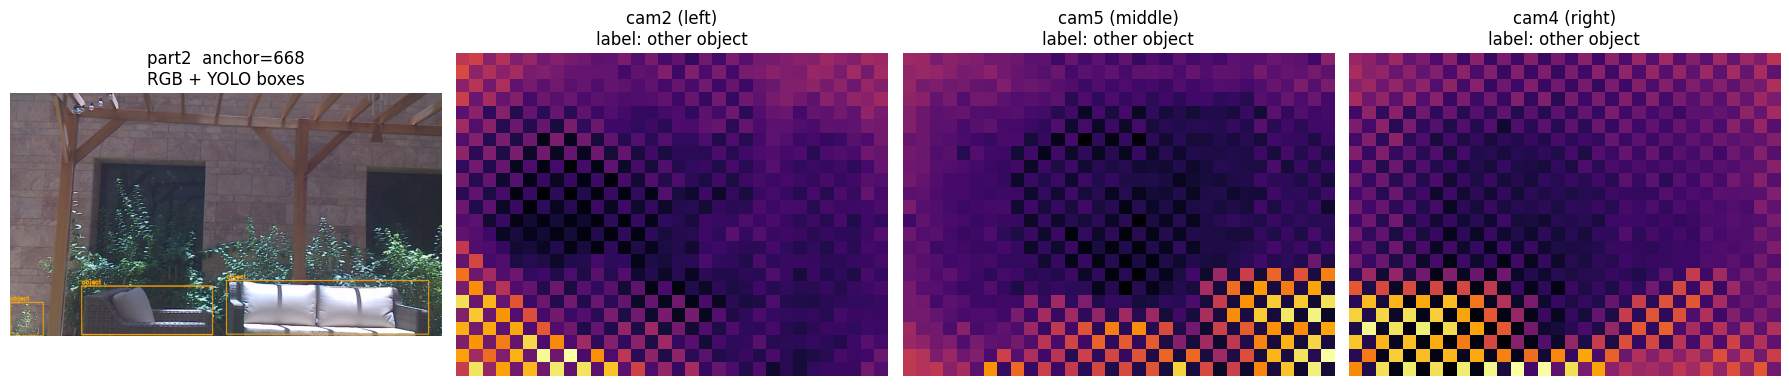

total: 3433 rows across 3 part(s)


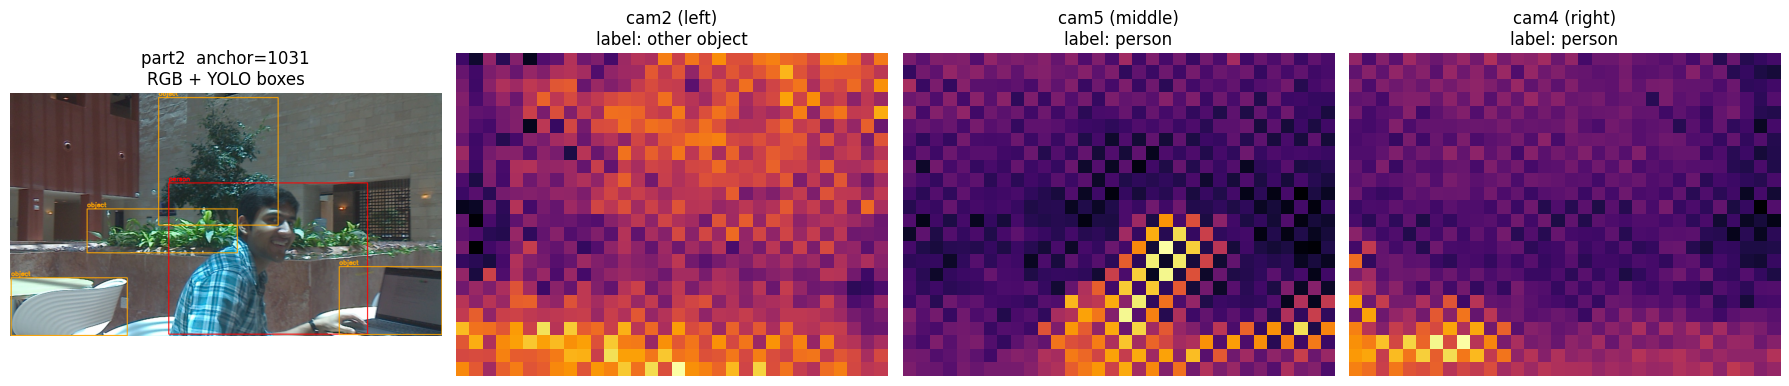

total: 3433 rows across 3 part(s)


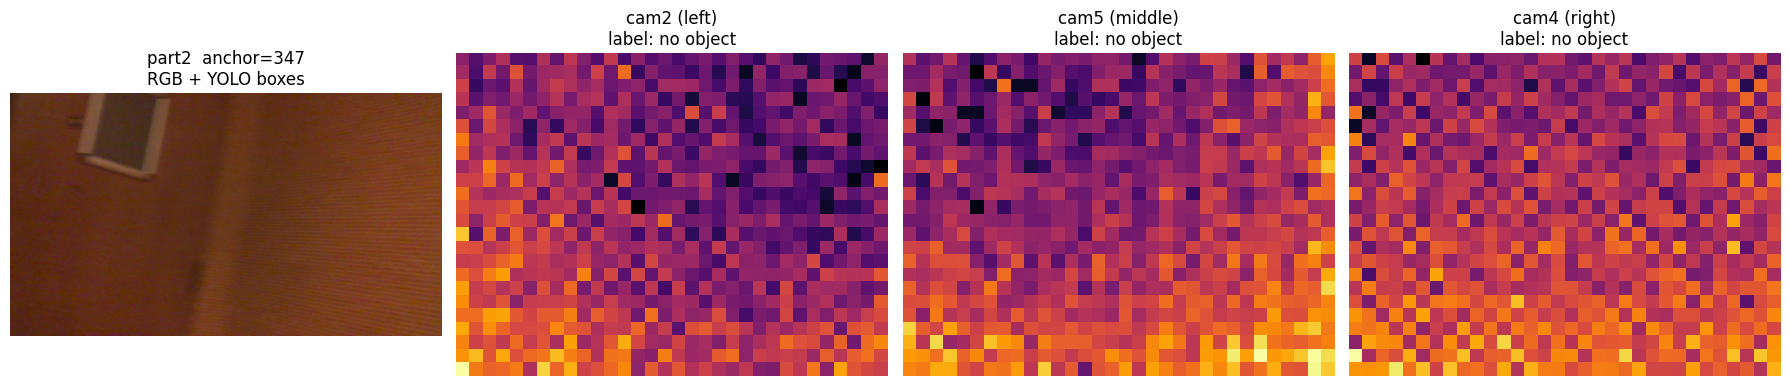

In [7]:
_CLASS_COLOR = {0: (150, 150, 150), 1: (0, 0, 255), 2: (0, 165, 255)}   # gray / red / orange, BGR
_CLASS_LABEL_NAME = {0: "no object", 1: "person", 2: "other object"}


def preview_random_sample(row=None, seed=RANDOM_SEED):
    '''row: a sync row (defaults to a random one with a usable RGB match). Shows:
      - RGB frame with raw YOLO boxes (red=person, orange=other), thermal footprints outlined
      - each active camera's raw thermal tile, titled with its derived class label
    '''
    if row is None:
        candidates = [r for r in load_all_sync_rows() if rgb_gap_ok(r)]
        row = random.Random(seed).choice(candidates)

    part = row["_part"]
    anchor_index = int(row["anchor_index"])
    class_vec, mask_vec = get_or_compute_label(row, keep_boxes=True)
    boxes_by_cam = _label_boxes_cache.get(_sample_key(row), {})

    rgb_img = cv2.imread(str(CAPTURE_PARTS[part]["rgb_dir"] / row["rgb_files"])) if rgb_gap_ok(row) else None
    tiles = load_camera_tiles(part, anchor_index)

    n_panels = 1 + len(CAM_ORDER_LEFT_TO_RIGHT)
    fig, axes = plt.subplots(1, n_panels, figsize=(4.5 * n_panels, 4.5))

    if rgb_img is not None:
        annotated = rgb_img.copy()
        seen_boxes = set()
        for cam_id, boxes in boxes_by_cam.items():
            for box, cls, is_person in boxes:
                box_key = tuple(np.round(box, 1))
                if box_key in seen_boxes:
                    continue
                seen_boxes.add(box_key)
                x1, y1, x2, y2 = (int(v) for v in box)
                color = (0, 0, 255) if is_person else (0, 165, 255)
                cv2.rectangle(annotated, (x1, y1), (x2, y2), color, 2)
                cv2.putText(annotated, "person" if is_person else "object", (x1, max(0, y1 - 6)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
        axes[0].imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
        axes[0].set_title(f"{part}  anchor={anchor_index}\nRGB + YOLO boxes")
    else:
        axes[0].text(0.5, 0.5, "no synced RGB frame", ha="center", va="center")
    axes[0].axis("off")

    for i, cam_id in enumerate(CAM_ORDER_LEFT_TO_RIGHT):
        ax = axes[i + 1]
        ax.imshow(tiles[i], cmap="inferno")
        cls = int(class_vec[i])
        masked = mask_vec[i] > 0
        title = f"cam{cam_id} ({CAM_TO_DIRECTION[cam_id]})\n"
        title += f"label: {_CLASS_LABEL_NAME[cls]}" if masked else "label: -- (unsupervised)"
        ax.set_title(title, color=("black" if masked else "gray"))
        ax.axis("off")

    plt.tight_layout()
    plt.show()


if USE_REAL_LABELS:
    for _ in range(3):
        preview_random_sample(seed=random.randint(0, 99999))
else:
    print("Skipping rich preview -- naive fallback mode (no RGB calibration files found yet).")


## Section 7 — Class distribution across left / middle / right

The natural (not rebalanced) 3-class distribution per camera direction, over the full combined
dataset. Useful before training to see whether `person` is rare enough to need a weighted loss,
and whether any one direction is structurally biased toward more obstructions (e.g. a doorway
on the right side of the rig).

In [8]:
def show_direction_class_distribution(rows, label="all data"):
    '''Stacked bar chart: per-direction (left/middle/right) counts of no_object/person/other,
    plus a 'no RGB label' bucket for samples where that camera's mask is 0. Requires labels to
    be precomputed already.'''
    counts = {d: {c: 0 for c in range(NUM_CLASSES)} | {"unsupervised": 0} for d in DIRECTIONS}
    for row in rows:
        class_vec, mask_vec = get_or_compute_label(row)
        for i, cam_id in enumerate(CAM_ORDER_LEFT_TO_RIGHT):
            d = CAM_TO_DIRECTION[cam_id]
            if mask_vec[i] > 0:
                counts[d][int(class_vec[i])] += 1
            else:
                counts[d]["unsupervised"] += 1

    df = pd.DataFrame(counts).T
    df = df.rename(columns={0: "no_object", 1: "person", 2: "other_object"})
    df = df[["no_object", "person", "other_object", "unsupervised"]]
    print(f"[{label}] per-direction class counts:\n{df}\n")

    fig, ax = plt.subplots(figsize=(7, 4.5))
    colors = ["#9E9E9E", "#E53935", "#FB8C00", "#455A64"]
    df.plot(kind="bar", stacked=True, ax=ax, color=colors)
    ax.set_title(f"{label} — class distribution by camera direction")
    ax.set_ylabel("samples")
    ax.set_xlabel("direction")
    ax.legend(title="class", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
    return df


def show_person_vs_other_rates(rows, label="all data"):
    '''Simple per-direction person-rate / other-object-rate bar chart, normalized by the
    number of supervised (masked) samples for that direction -- easier to compare directions
    with different total supervised counts at a glance.'''
    df = show_direction_class_distribution(rows, label=label + " (raw counts)")
    supervised = df[["no_object", "person", "other_object"]].sum(axis=1)
    rates = df[["person", "other_object"]].div(supervised.replace(0, np.nan), axis=0)

    fig, ax = plt.subplots(figsize=(6, 4))
    rates.plot(kind="bar", ax=ax, color=["#E53935", "#FB8C00"])
    ax.set_ylabel("rate (of supervised samples)")
    ax.set_title(f"{label} — person vs. other-object rate by direction")
    plt.tight_layout()
    plt.show()
    return rates


## Section 8 — Datasets

`StitchedPanoramaDataset` feeds Baseline 1 (2-channel stitched panorama). `TileDataset` feeds
Baselines 2-4 (per-camera raw tiles, `[NUM_CAMS, 1, H, W]`). Both call `precompute_labels` first
(required — see its docstring re: CUDA + forked DataLoader workers) and return integer class
vectors instead of binary labels.

In [9]:
class StitchedPanoramaDataset(Dataset):
    '''Baseline 1 input: [2, H, W] stitched panorama + validity mask.'''

    def __init__(self, sync_rows):
        self.sync_rows = sync_rows

    def __len__(self):
        return len(self.sync_rows)

    def __getitem__(self, idx):
        row = self.sync_rows[idx]
        part, anchor_index = row["_part"], int(row["anchor_index"])
        panorama = load_panorama(part, anchor_index)
        tensor = build_stitched_input_tensor(panorama)
        class_vec, mask_vec = get_or_compute_label(row)
        return (torch.from_numpy(tensor), torch.from_numpy(class_vec), torch.from_numpy(mask_vec))


class TileDataset(Dataset):
    '''Baselines 2/3/4 input: [NUM_CAMS, 1, H, W] raw per-camera tiles, unstitched.'''

    def __init__(self, sync_rows, cam_order=None):
        self.sync_rows = sync_rows
        self.cam_order = cam_order or CAM_ORDER_LEFT_TO_RIGHT

    def __len__(self):
        return len(self.sync_rows)

    def __getitem__(self, idx):
        row = self.sync_rows[idx]
        part, anchor_index = row["_part"], int(row["anchor_index"])
        tiles = load_camera_tiles(part, anchor_index, cam_order=self.cam_order)
        tensor = build_input_tensor(tiles)
        class_vec, mask_vec = get_or_compute_label(row)
        return (torch.from_numpy(tensor), torch.from_numpy(class_vec), torch.from_numpy(mask_vec))


## Section 9 — Load & split the data

Blocked train/val split (val samples spread across blocks of the whole combined session, not
just the chronological tail) -- same fix used in the source notebooks.

total: 3433 rows across 3 part(s)
train samples: 2752  val samples: 681
Precomputing labels for 3430 sample(s) (running YOLO once per frame)...
done.
[train + val (combined)] per-direction class counts:
        no_object  person  other_object  unsupervised
left         2178     125          1052            78
middle       1297     400          1658            78
right        2258      95          1002            78



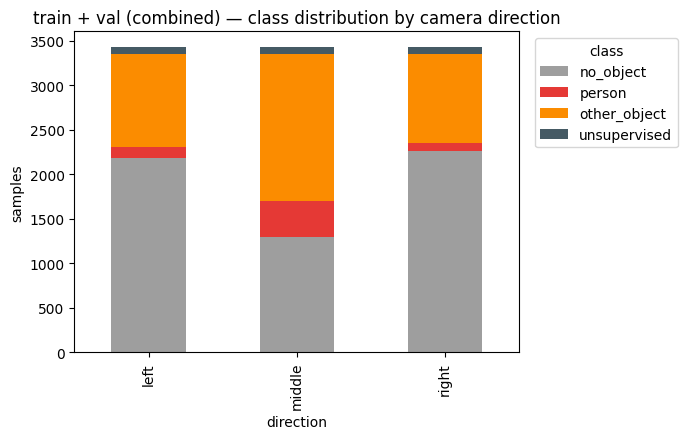

[train + val (combined) (raw counts)] per-direction class counts:
        no_object  person  other_object  unsupervised
left         2178     125          1052            78
middle       1297     400          1658            78
right        2258      95          1002            78



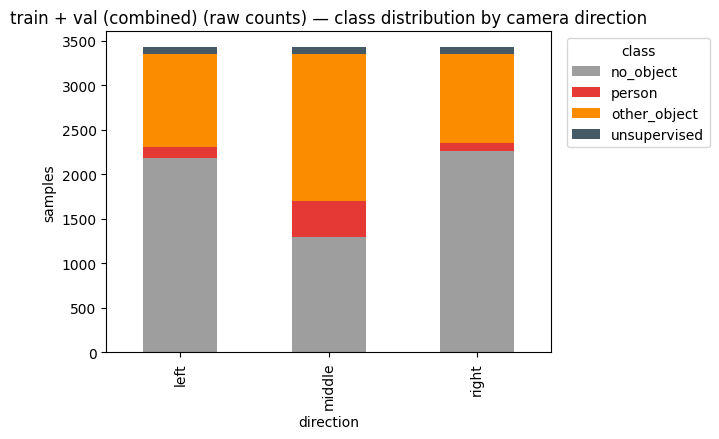

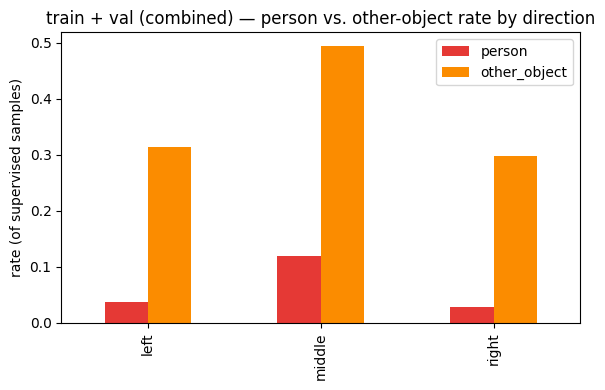

Loaders ready -- train batches: 43  val batches: 11


In [10]:
sync_rows = load_all_sync_rows()  # combines every discovered part, already shuffled

if SMOKE_TEST:
    print(f"*** SMOKE TEST MODE: using {SMOKE_TEST_N_SAMPLES} samples, "
          f"{SMOKE_TEST_EPOCHS} epoch(s), batch_size={SMOKE_TEST_BATCH_SIZE}. "
          f"Set SMOKE_TEST=False for a real run. ***")
    sync_rows = sync_rows[:SMOKE_TEST_N_SAMPLES]
    EFFECTIVE_EPOCHS = SMOKE_TEST_EPOCHS
    EFFECTIVE_BATCH_SIZE = SMOKE_TEST_BATCH_SIZE
    EFFECTIVE_NUM_WORKERS = 0
else:
    EFFECTIVE_EPOCHS = EPOCHS
    EFFECTIVE_BATCH_SIZE = BATCH_SIZE
    EFFECTIVE_NUM_WORKERS = NUM_WORKERS


def blocked_train_val_split(rows, val_frac=VAL_FRAC, n_blocks=N_SPLIT_BLOCKS):
    n = len(rows)
    block_size = max(1, n // n_blocks)
    train_rows, val_rows = [], []
    for start in range(0, n, block_size):
        block = rows[start:start + block_size]
        n_val = max(1, int(len(block) * val_frac)) if len(block) > 1 else 0
        if n_val == 0:
            train_rows.extend(block)
        else:
            train_rows.extend(block[:-n_val])
            val_rows.extend(block[-n_val:])
    if not val_rows:
        val_rows = train_rows[-1:]
    return train_rows, val_rows


if SMOKE_TEST:
    n_total = len(sync_rows)
    n_train = max(1, int(0.8 * n_total))
    train_rows, val_rows = sync_rows[:n_train], sync_rows[n_train:]
    if not val_rows:
        val_rows = train_rows[-1:]
else:
    train_rows, val_rows = blocked_train_val_split(sync_rows)

print(f"train samples: {len(train_rows)}  val samples: {len(val_rows)}")

# CRITICAL: must happen before any DataLoader(num_workers>0) below.
precompute_labels(train_rows + val_rows)

# ---- visualizations from Sections 6/7, now that labels are cached ----
show_direction_class_distribution(train_rows + val_rows, label="train + val (combined)")
show_person_vs_other_rates(train_rows + val_rows, label="train + val (combined)")

stitched_train_ds = StitchedPanoramaDataset(train_rows)
stitched_val_ds = StitchedPanoramaDataset(val_rows)
tile_train_ds = TileDataset(train_rows)
tile_val_ds = TileDataset(val_rows)

dl_kw = dict(batch_size=EFFECTIVE_BATCH_SIZE, num_workers=EFFECTIVE_NUM_WORKERS, pin_memory=True)
stitched_tr_ld = DataLoader(stitched_train_ds, shuffle=True, **dl_kw)
stitched_va_ld = DataLoader(stitched_val_ds, shuffle=False, **dl_kw)
tile_tr_ld = DataLoader(tile_train_ds, shuffle=True, **dl_kw)
tile_va_ld = DataLoader(tile_val_ds, shuffle=False, **dl_kw)
print(f"Loaders ready -- train batches: {len(tile_tr_ld)}  val batches: {len(tile_va_ld)}")


## Section 10 — Shared training / eval helpers (3-class, masked)

Every model below outputs `[B, NUM_CAMS, NUM_CLASSES]` logits. Loss is **masked
cross-entropy**: only camera-slots with `mask=1` (real RGB-derived label) contribute. Metrics
report **macro F1 across the 2 positive classes** (person, other_object) per camera — mirroring
the source notebooks' "Masked Macro F1" convention but now multi-class — plus a full per-class
breakdown and a confusion matrix. `derive_clear` becomes `derive_no_object`: a camera-slot is
"clear" if its predicted class is 0.

In [11]:
def masked_ce_loss(logits, class_labels, mask, class_weight=None):
    '''logits: [B, NUM_CAMS, NUM_CLASSES]. class_labels: [B, NUM_CAMS] (int64). mask: [B, NUM_CAMS].
    Cross-entropy per camera-slot, masked by RGB-overlap/sync validity, averaged only over
    valid slots.'''
    B, C, K = logits.shape
    per_element = F.cross_entropy(
        logits.reshape(B * C, K), class_labels.reshape(B * C).long(),
        weight=class_weight, reduction="none",
    ).reshape(B, C)
    masked = per_element * mask
    denom = mask.sum().clamp_min(1.0)
    return masked.sum() / denom


def masked_macro_f1_multiclass(preds, trues, masks, positive_classes=(1, 2)):
    '''preds/trues/masks: [N, NUM_CAMS] numpy int arrays (masks float). Per-camera macro F1 over
    `positive_classes` only (skips a camera entirely if it has zero valid rows), then averaged
    across cameras that had at least one -- mirrors the source notebooks' masked_macro_f1, now
    multiclass via sklearn's per-class F1 with average=None, restricted to the positive classes.'''
    from sklearn.metrics import f1_score as _f1
    cam_f1s = []
    for i in range(preds.shape[1]):
        valid = masks[:, i] > 0
        if valid.sum() == 0:
            continue
        per_class = _f1(trues[valid, i], preds[valid, i], labels=list(positive_classes),
                         average=None, zero_division=0)
        cam_f1s.append(float(np.mean(per_class)))
    return float(np.mean(cam_f1s)) if cam_f1s else 0.0


def derive_no_object(class_logits):
    '''class_logits: [B, NUM_CAMS, NUM_CLASSES]. Hard rule (consistent with the source
    notebooks' derive_clear): the per-camera argmax class, with 'Clear' meaning every camera's
    argmax is 0 (no_object).'''
    pred_class = class_logits.argmax(dim=-1)
    return (pred_class.sum(dim=1) == 0).float(), pred_class


@torch.no_grad()
def evaluate_model(model, loader, model_input_kind="tile"):
    '''model_input_kind: 'tile' ([B,NUM_CAMS,1,H,W]) or 'stitched' ([B,2,H,W], cropped inside
    the model). Returns a dict with macro_f1, per-class predictions/trues/masks, and a 'clear'
    (no_object-everywhere) F1 where well-defined.'''
    model.eval()
    all_logits, all_labels, all_masks = [], [], []
    for x, y, m in loader:
        x = x.to(device)
        logits = model(x).cpu()  # [B, NUM_CAMS, NUM_CLASSES]
        all_logits.append(logits)
        all_labels.append(y)
        all_masks.append(m)
    if not all_labels:
        return {"macro_f1": 0., "preds": np.zeros((0, NUM_CAMS)), "trues": np.zeros((0, NUM_CAMS)),
                "masks": np.zeros((0, NUM_CAMS)), "clear_f1": None}
    logits = torch.cat(all_logits)
    labels = torch.cat(all_labels)
    masks = torch.cat(all_masks)
    pred_class = logits.argmax(dim=-1)

    p_np, t_np, m_np = pred_class.numpy(), labels.numpy(), masks.numpy()
    macro_f1 = masked_macro_f1_multiclass(p_np, t_np, m_np)

    no_object_pred, _ = derive_no_object(logits)
    full_coverage = masks.all(dim=1)
    if full_coverage.sum().item() > 0:
        no_object_true = (labels[full_coverage].sum(dim=1) == 0).float()
        clear_f1 = f1_score(no_object_true.numpy(), no_object_pred[full_coverage].numpy(), zero_division=0)
    else:
        clear_f1 = None

    return {"macro_f1": macro_f1, "clear_f1": clear_f1, "preds": p_np, "trues": t_np, "masks": m_np}


def train_classifier_model(model, name, tr, va, epochs=EPOCHS, lr=LR, class_weight=None):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    best_f1, best_w = -1., copy.deepcopy(model.state_dict())
    cw = class_weight.to(device) if class_weight is not None else None
    for ep in range(epochs):
        model.train(); running = 0.; n_seen = 0
        for x, y, mask in tr:
            x, y, mask = x.to(device), y.to(device), mask.to(device)
            opt.zero_grad()
            loss = masked_ce_loss(model(x), y, mask, class_weight=cw)
            loss.backward(); opt.step()
            running += loss.item() * len(y); n_seen += len(y)
        sch.step()
        vm = evaluate_model(model, va)
        if vm["macro_f1"] > best_f1:
            best_f1 = vm["macro_f1"]
            best_w = copy.deepcopy(model.state_dict())
        if (ep + 1) % 5 == 0 or ep == 0:
            print(f"  [{name}] ep {ep+1:02d}/{epochs}  "
                  f"train_loss={running/max(n_seen,1):.4f}  val_macro_f1={vm['macro_f1']:.3f}")
    model.load_state_dict(best_w)
    return model


def count_params(m):
    return sum(p.numel() for p in m.parameters())


def measure_latency(model, dummy_input, n_runs=200):
    m = model.cpu().eval()
    with torch.no_grad():
        for _ in range(20):
            m(dummy_input)
        t0 = time.perf_counter()
        for _ in range(n_runs):
            m(dummy_input)
    model.to(device)
    return (time.perf_counter() - t0) / n_runs * 1000


def save_model(model, tag):
    path = MODEL_DIR / f"{tag}.pt"
    torch.save(model.state_dict(), path)
    print(f"  Saved -> {path}")


def per_camera_report(result, label, class_names=CLASS_NAMES):
    p, t, msk = result["preds"], result["trues"], result["masks"]
    print(f"\nPer-camera report — {label}")
    for i, cam_id in enumerate(CAM_ORDER_LEFT_TO_RIGHT):
        valid = msk[:, i] > 0
        n = int(valid.sum())
        if n == 0:
            print(f"  cam{cam_id} ({CAM_TO_DIRECTION[cam_id]}):  -- (no real labels in this val set)")
            continue
        per_class_f1 = f1_score(t[valid, i], p[valid, i], labels=[0, 1, 2], average=None, zero_division=0)
        pos_macro = float(np.mean([per_class_f1[1], per_class_f1[2]]))
        print(f"  cam{cam_id} ({CAM_TO_DIRECTION[cam_id]}, n={n}):  "
              f"F1[no_object]={per_class_f1[0]:.3f}  F1[person]={per_class_f1[1]:.3f}  "
              f"F1[other]={per_class_f1[2]:.3f}  macro(person+other)={pos_macro:.3f}")
    print(f"  {'Overall macro F1':<28} {result['macro_f1']:.3f}")


def plot_confusion(result, label):
    p, t, msk = result["preds"], result["trues"], result["masks"]
    valid = msk.reshape(-1) > 0
    cm = confusion_matrix(t.reshape(-1)[valid], p.reshape(-1)[valid], labels=[0, 1, 2])
    fig, ax = plt.subplots(figsize=(4, 4))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
    ax.set_yticks(range(3)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(f"Confusion matrix — {label}")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.tight_layout()
    plt.show()


## Section 11 — Model 1: Baseline 1 (stitched panorama)

One shared backbone + head, applied to each camera's footprint-bbox crop of the stitched
panorama. Same architecture as `baseline1-3cams-new` (depth-5 backbone, spatial-preserving
`(3,4)` pooling), with the head now outputting `NUM_CLASSES` logits per camera instead of 1.

In [12]:
class ThermalBackbone(nn.Module):
    def __init__(self, in_channels=2, pool_size=(3, 4)):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, 16, 5, padding=2); self.bn1 = nn.BatchNorm2d(16)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1);          self.bn2 = nn.BatchNorm2d(32)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1);          self.bn3 = nn.BatchNorm2d(64)
        self.conv4 = nn.Conv2d(64, 64, 3, padding=1);          self.bn4 = nn.BatchNorm2d(64)
        self.conv5 = nn.Conv2d(64, 64, 3, padding=1);          self.bn5 = nn.BatchNorm2d(64)
        self.pool = nn.MaxPool2d(2)
        self.pool_size = pool_size

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = F.relu(self.bn3(self.conv3(x)))
        x = F.relu(self.bn4(self.conv4(x)))
        x = F.relu(self.bn5(self.conv5(x)))
        x = F.adaptive_avg_pool2d(x, self.pool_size)
        return x.flatten(1)  # [B, 64*3*4]


class QuadrantHead3Class(nn.Module):
    def __init__(self, in_features=64 * 3 * 4, num_classes=NUM_CLASSES):
        super().__init__()
        self.fc1 = nn.Linear(in_features, 64)
        self.dropout = nn.Dropout(0.3)
        self.fc2 = nn.Linear(64, num_classes)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)  # [B, NUM_CLASSES] logits


class StitchedBaselineModel(nn.Module):
    '''One shared backbone + head, applied per camera's footprint-bbox crop. Outputs
    [B, NUM_CAMS, NUM_CLASSES].'''

    def __init__(self, crop_size=(24, 32)):
        super().__init__()
        self.backbone = ThermalBackbone(in_channels=2)
        self.head = QuadrantHead3Class()
        self.crop_size = crop_size

    def _extract_quadrant(self, x, bbox):
        x1, y1, x2, y2 = (int(round(v)) for v in bbox)
        x1, y1 = max(x1, 0), max(y1, 0)
        patch = x[:, :, y1:y2, x1:x2]
        if patch.shape[-2:] != self.crop_size:
            patch = F.interpolate(patch, size=self.crop_size, mode="nearest")
        return patch

    def forward(self, x):
        logits = []
        for cam_id in CAM_ORDER_LEFT_TO_RIGHT:
            bbox = CAM_FOOTPRINTS[cam_id]["bbox"]
            patch = self._extract_quadrant(x, bbox)
            feat = self.backbone(patch)
            logits.append(self.head(feat))
        return torch.stack(logits, dim=1)  # [B, NUM_CAMS, NUM_CLASSES]


dummy_stitched = torch.zeros(2, 2, PANORAMA_H, PANORAMA_W)
m1 = StitchedBaselineModel()
out1 = m1(dummy_stitched)
print(f"Baseline 1 output shape: {out1.shape}  | params: {count_params(m1):,}")


Baseline 1 output shape: torch.Size([2, 3, 3])  | params: 147,699


In [13]:
# ---- class balance check (Baseline 1) -- pos_weight style, but for 3-class CE ----
class_counts = torch.zeros(NUM_CLASSES)
for row in train_rows + val_rows:
    class_vec, mask_vec = get_or_compute_label(row)
    for i in range(NUM_CAMS):
        if mask_vec[i] > 0:
            class_counts[int(class_vec[i])] += 1
print("class counts (train+val, masked only):",
      {CLASS_NAMES[c]: int(class_counts[c]) for c in range(NUM_CLASSES)})

# inverse-frequency class weight, capped so a rare class doesn't blow up the gradient
CLASS_WEIGHT_CAP = 20.0
total = class_counts.sum().clamp_min(1.0)
class_weight = (total / (class_counts.clamp_min(1.0) * NUM_CLASSES)).clamp(max=CLASS_WEIGHT_CAP)
print("class_weight:", {CLASS_NAMES[c]: round(class_weight[c].item(), 2) for c in range(NUM_CLASSES)})


class counts (train+val, masked only): {'no_object': 5733, 'person': 620, 'other_object': 3712}
class_weight: {'no_object': 0.59, 'person': 5.41, 'other_object': 0.9}


TRAINING BASELINE 1 -- Stitched panorama
  [baseline1_stitched] ep 01/30  train_loss=1.0580  val_macro_f1=0.179
  [baseline1_stitched] ep 05/30  train_loss=0.8863  val_macro_f1=0.320
  [baseline1_stitched] ep 10/30  train_loss=0.7845  val_macro_f1=0.245
  [baseline1_stitched] ep 15/30  train_loss=0.7016  val_macro_f1=0.315
  [baseline1_stitched] ep 20/30  train_loss=0.6363  val_macro_f1=0.414
  [baseline1_stitched] ep 25/30  train_loss=0.5643  val_macro_f1=0.418
  [baseline1_stitched] ep 30/30  train_loss=0.5437  val_macro_f1=0.383
  Saved -> /kaggle/working/saved_models_unified/baseline1_stitched.pt

Baseline 1 -- VAL macro_f1=0.4601  clear_f1=0.626984126984127  latency=3.40ms  params=147,699

Per-camera report — Baseline 1 (stitched)
  cam2 (left, n=666):  F1[no_object]=0.828  F1[person]=0.333  F1[other]=0.328  macro(person+other)=0.331
  cam5 (middle, n=666):  F1[no_object]=0.628  F1[person]=0.549  F1[other]=0.581  macro(person+other)=0.565
  cam4 (right, n=666):  F1[no_object]=0.78

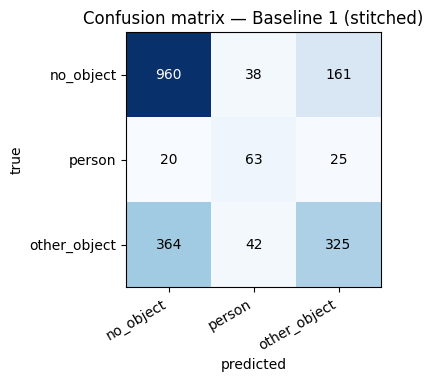

In [14]:
print("="*60); print("TRAINING BASELINE 1 -- Stitched panorama"); print("="*60)

baseline1_model = StitchedBaselineModel().to(device)
baseline1_model = train_classifier_model(
    baseline1_model, "baseline1_stitched", stitched_tr_ld, stitched_va_ld,
    epochs=EFFECTIVE_EPOCHS, class_weight=class_weight,
)
save_model(baseline1_model, "baseline1_stitched")

baseline1_result = evaluate_model(baseline1_model, stitched_va_ld)
baseline1_latency = measure_latency(baseline1_model, dummy_stitched[:1])
print(f"\nBaseline 1 -- VAL macro_f1={baseline1_result['macro_f1']:.4f}  "
      f"clear_f1={baseline1_result['clear_f1']}  latency={baseline1_latency:.2f}ms  "
      f"params={count_params(baseline1_model):,}")
per_camera_report(baseline1_result, "Baseline 1 (stitched)")
plot_confusion(baseline1_result, "Baseline 1 (stitched)")


## Section 12 — Shared `FlexBackbone` building block

Ported from `feature-fusion-real-data`, unchanged. Used by Baseline 2 (Output Fusion), Feature
Fusion, and the camera-identity classifier in Section 15.

In [15]:
ACT_MAP = {
    "relu":      nn.ReLU,
    "gelu":      nn.GELU,
    "leakyrelu": lambda: nn.LeakyReLU(0.1),
}


def make_conv_block(in_ch, out_ch, act_fn):
    return nn.Sequential(nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), act_fn())


class FlexBackbone(nn.Module):
    '''depth controls how many downsampling blocks, width_mult scales all channel counts.
    in_channels is always 1 (single raw thermal tile, no validity-mask channel).'''
    BASE_CHANNELS = [16, 32, 64, 128, 256]

    def __init__(self, depth=3, width_mult=1.0, act="relu"):
        super().__init__()
        assert 2 <= depth <= 5, "depth must be 2-5"
        act_fn = ACT_MAP[act]
        channels = [max(4, int(c * width_mult)) for c in self.BASE_CHANNELS[:depth]]
        self.blocks = nn.ModuleList()
        in_ch = 1
        for i, out_ch in enumerate(channels):
            pool = (i < depth - 1)
            block_layers = [make_conv_block(in_ch, out_ch, act_fn)]
            if pool:
                block_layers.append(nn.MaxPool2d(2))
            self.blocks.append(nn.Sequential(*block_layers))
            in_ch = out_ch
        self.out_channels = channels

    def forward(self, x):
        feats = []
        for block in self.blocks:
            x = block(x)
            feats.append(x)
        return feats


def backbone_feature_dims(depth=3, width_mult=1.0, act="relu"):
    b = FlexBackbone(depth, width_mult, act)
    with torch.no_grad():
        feats = b(torch.zeros(1, 1, SENSOR_H, SENSOR_W))
    return [f.shape[1] for f in feats], [tuple(f.shape[-2:]) for f in feats]


ch, sz = backbone_feature_dims(3, 1.0)
print(f"Baseline backbone: channels={ch}, spatial={sz}")


Baseline backbone: channels=[16, 32, 64], spatial=[(12, 16), (6, 8), (6, 8)]


## Section 13 — Model 2: Baseline 2 (Output Fusion)

Each camera tile goes through the **same shared `FlexBackbone`**, but each camera gets its
**own independent classification head** (not shared) — so a camera can specialize, but no
information crosses between cameras until after each one has already committed to its own
`NUM_CLASSES` logits. Those `NUM_CAMS * NUM_CLASSES` numbers are concatenated and passed through
a small **fusion MLP** that produces the final, corrected per-camera logits.

This is "fuse decisions, not features" — the architectural floor that Feature Fusion (Section
14) is meant to beat, since by the time the fusion MLP sees anything, every camera's spatial
detail has already been compressed away by global average pooling inside its own head.

In [16]:
class PerCameraHead(nn.Module):
    '''GAP -> small MLP -> NUM_CLASSES logits, for ONE camera's own feature maps.'''

    def __init__(self, feature_dims, hidden=64, dropout=0.3, n_out=NUM_CLASSES):
        super().__init__()
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(sum(feature_dims), hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, n_out))

    def forward(self, features):
        return self.fc(torch.cat([self.pool(f).flatten(1) for f in features], dim=1))


class OutputFusionModel(nn.Module):
    '''Baseline 2. Shared backbone, independent per-camera heads, decision-level fusion MLP.
    Output: [B, NUM_CAMS, NUM_CLASSES].'''

    def __init__(self, depth=3, width_mult=1.0, act="relu",
                 head_hidden=64, head_dropout=0.3, fusion_hidden=64):
        super().__init__()
        self.backbone = FlexBackbone(depth, width_mult, act)
        per_dims = self.backbone.out_channels
        self.per_cam_heads = nn.ModuleList([
            PerCameraHead(per_dims, hidden=head_hidden, dropout=head_dropout) for _ in range(NUM_CAMS)
        ])
        fusion_in = NUM_CAMS * NUM_CLASSES
        self.fusion_mlp = nn.Sequential(
            nn.Linear(fusion_in, fusion_hidden), nn.ReLU(), nn.Dropout(head_dropout),
            nn.Linear(fusion_hidden, fusion_in),
        )

    def forward(self, x):
        # x: [B, NUM_CAMS, 1, H, W]
        per_cam_logits = []
        for i in range(NUM_CAMS):
            feats = self.backbone(x[:, i])
            per_cam_logits.append(self.per_cam_heads[i](feats))  # [B, NUM_CLASSES]
        concat_logits = torch.cat(per_cam_logits, dim=1)         # [B, NUM_CAMS*NUM_CLASSES]
        fused = self.fusion_mlp(concat_logits)
        return fused.view(-1, NUM_CAMS, NUM_CLASSES)


dummy_tile = torch.zeros(2, NUM_CAMS, 1, SENSOR_H, SENSOR_W)
m2 = OutputFusionModel()
out2 = m2(dummy_tile)
print(f"Baseline 2 (Output Fusion) output shape: {out2.shape}  | params: {count_params(m2):,}")


Baseline 2 (Output Fusion) output shape: torch.Size([2, 3, 3])  | params: 47,026


TRAINING BASELINE 2 -- Output Fusion
  [baseline2_output_fusion] ep 01/30  train_loss=1.0573  val_macro_f1=0.033
  [baseline2_output_fusion] ep 05/30  train_loss=0.9308  val_macro_f1=0.207
  [baseline2_output_fusion] ep 10/30  train_loss=0.8735  val_macro_f1=0.285
  [baseline2_output_fusion] ep 15/30  train_loss=0.8499  val_macro_f1=0.275
  [baseline2_output_fusion] ep 20/30  train_loss=0.8086  val_macro_f1=0.316
  [baseline2_output_fusion] ep 25/30  train_loss=0.7918  val_macro_f1=0.390
  [baseline2_output_fusion] ep 30/30  train_loss=0.7700  val_macro_f1=0.393
  Saved -> /kaggle/working/saved_models_unified/baseline2_output_fusion.pt

Baseline 2 -- VAL macro_f1=0.4008  clear_f1=0.007575757575757576  latency=2.51ms  params=47,026

Per-camera report — Baseline 2 (Output Fusion)
  cam2 (left, n=666):  F1[no_object]=0.767  F1[person]=0.417  F1[other]=0.459  macro(person+other)=0.438
  cam5 (middle, n=666):  F1[no_object]=0.008  F1[person]=0.311  F1[other]=0.637  macro(person+other)=0.474

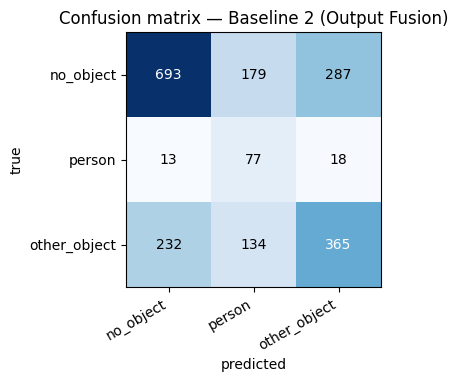

In [17]:
print("="*60); print("TRAINING BASELINE 2 -- Output Fusion"); print("="*60)

baseline2_model = OutputFusionModel().to(device)
baseline2_model = train_classifier_model(
    baseline2_model, "baseline2_output_fusion", tile_tr_ld, tile_va_ld,
    epochs=EFFECTIVE_EPOCHS, class_weight=class_weight,
)
save_model(baseline2_model, "baseline2_output_fusion")

baseline2_result = evaluate_model(baseline2_model, tile_va_ld)
baseline2_latency = measure_latency(baseline2_model, dummy_tile[:1])
print(f"\nBaseline 2 -- VAL macro_f1={baseline2_result['macro_f1']:.4f}  "
      f"clear_f1={baseline2_result['clear_f1']}  latency={baseline2_latency:.2f}ms  "
      f"params={count_params(baseline2_model):,}")
per_camera_report(baseline2_result, "Baseline 2 (Output Fusion)")
plot_confusion(baseline2_result, "Baseline 2 (Output Fusion)")


## Section 14 — Model 3: Feature Fusion (+ ablation sweep)

Ported from `feature-fusion-real-data`. Shared-weight `FlexBackbone` runs on each camera tile;
feature maps at every level are concatenated across cameras and projected back to the original
channel count via 1x1 conv, then a **shared** head produces `[B, NUM_CAMS, NUM_CLASSES]` logits.
Same depth/width/activation/head/dropout ablation axes as the source notebook, reproduced here
against the 3-class label.

In [18]:
class FlexClassHead3Class(nn.Module):
    def __init__(self, feature_dims, hidden=128, dropout=0.3, n_out_per_cam=NUM_CLASSES):
        super().__init__()
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.n_out_per_cam = n_out_per_cam
        self.fc = nn.Sequential(
            nn.Linear(sum(feature_dims), hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, NUM_CAMS * n_out_per_cam))

    def forward(self, features):
        out = self.fc(torch.cat([self.pool(f).flatten(1) for f in features], dim=1))
        return out.view(-1, NUM_CAMS, self.n_out_per_cam)


class FeatureFusionModel(nn.Module):
    '''Shared-weight FlexBackbone runs on each of the NUM_CAMS camera tiles independently.
    Feature maps at each level are concatenated across cameras, then projected back to the
    original channel count via a 1x1 conv before the shared head. Output:
    [B, NUM_CAMS, NUM_CLASSES].'''

    def __init__(self, depth=3, width_mult=1.0, act="relu", head_hidden=128, head_dropout=0.3):
        super().__init__()
        self.backbone = FlexBackbone(depth, width_mult, act)
        per_dims = self.backbone.out_channels
        self.proj = nn.ModuleList([nn.Conv2d(d * NUM_CAMS, d, 1) for d in per_dims])
        self.head = FlexClassHead3Class(per_dims, hidden=head_hidden, dropout=head_dropout)

    def forward(self, x):
        # x: [B, NUM_CAMS, 1, H, W]
        n_levels = len(self.backbone.out_channels)
        all_feats = [[] for _ in range(n_levels)]
        for i in range(NUM_CAMS):
            for lvl, f in enumerate(self.backbone(x[:, i])):
                all_feats[lvl].append(f)
        fused = [proj(torch.cat(lf, dim=1)) for proj, lf in zip(self.proj, all_feats)]
        return self.head(fused)


m3 = FeatureFusionModel(depth=3, width_mult=1.0)
out3 = m3(dummy_tile)
print(f"Feature Fusion baseline output shape: {out3.shape}  | params: {count_params(m3):,}")


Feature Fusion baseline output shape: torch.Size([2, 3, 3])  | params: 55,385


### Ablation variant configs

| Axis | Variants |
|---|---|
| **Depth** | 3 blocks (baseline), 4, 5 |
| **Width** | 0.5x, 1x (baseline), 1.5x, 2x |
| **Head capacity** | 64, 128 (baseline), 256, 512 |
| **Activation** | ReLU (baseline), GELU, LeakyReLU |
| **Regularization** | Dropout 0.1 / 0.3 (baseline) / 0.5 |

In [19]:
ff_results = {}

def run_ff_variant(key, label, **model_kwargs):
    print(f"\n{'='*60}\nFEATURE FUSION -- {label}\n{'='*60}")
    model = FeatureFusionModel(**model_kwargs)
    print(f"Params: {count_params(model):,}")
    train_classifier_model(model, key, tile_tr_ld, tile_va_ld, epochs=EFFECTIVE_EPOCHS,
                            class_weight=class_weight)
    save_model(model, f"ff_{key}")
    test_m = evaluate_model(model, tile_va_ld)
    lat = measure_latency(model, dummy_tile[:1])
    ff_results[key] = {
        "label": label, "macro_f1": test_m["macro_f1"], "clear_f1": test_m["clear_f1"],
        "preds": test_m["preds"], "trues": test_m["trues"], "masks": test_m["masks"],
        "params": count_params(model), "latency_ms": lat, "model": model,
    }
    print(f"  VAL  macro_f1={test_m['macro_f1']:.4f}  clear_f1={test_m['clear_f1']}  latency={lat:.2f}ms")
    return model


# ---- baseline ----
run_ff_variant("baseline", "Baseline (d=3, w=1x, relu, h=128, dr=0.3)",
                depth=3, width_mult=1.0, act="relu", head_hidden=128, head_dropout=0.3)



FEATURE FUSION -- Baseline (d=3, w=1x, relu, h=128, dr=0.3)
Params: 55,385
  [baseline] ep 01/30  train_loss=1.0316  val_macro_f1=0.191
  [baseline] ep 05/30  train_loss=0.8649  val_macro_f1=0.251
  [baseline] ep 10/30  train_loss=0.7884  val_macro_f1=0.295
  [baseline] ep 15/30  train_loss=0.7211  val_macro_f1=0.307
  [baseline] ep 20/30  train_loss=0.6862  val_macro_f1=0.287
  [baseline] ep 25/30  train_loss=0.6591  val_macro_f1=0.389
  [baseline] ep 30/30  train_loss=0.6434  val_macro_f1=0.396
  Saved -> /kaggle/working/saved_models_unified/ff_baseline.pt
  VAL  macro_f1=0.4315  clear_f1=0.18729096989966554  latency=1.69ms


FeatureFusionModel(
  (backbone): FlexBackbone(
    (blocks): ModuleList(
      (0): Sequential(
        (0): Sequential(
          (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU()
        )
        (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
      (1): Sequential(
        (0): Sequential(
          (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU()
        )
        (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
      (2): Sequential(
        (0): Sequential(
          (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)

In [20]:
# ---- ablation 1: depth ----
for depth in [2, 4, 5]:
    run_ff_variant(f"d{depth}_w1_relu_h128_dr03", f"depth={depth} (w=1x, relu, h=128, dr=0.3)",
                    depth=depth, width_mult=1.0, act="relu", head_hidden=128, head_dropout=0.3)



FEATURE FUSION -- depth=2 (w=1x, relu, h=128, dr=0.3)
Params: 16,217
  [d2_w1_relu_h128_dr03] ep 01/30  train_loss=1.0433  val_macro_f1=0.160
  [d2_w1_relu_h128_dr03] ep 05/30  train_loss=0.9467  val_macro_f1=0.278
  [d2_w1_relu_h128_dr03] ep 10/30  train_loss=0.9023  val_macro_f1=0.346
  [d2_w1_relu_h128_dr03] ep 15/30  train_loss=0.8475  val_macro_f1=0.293
  [d2_w1_relu_h128_dr03] ep 20/30  train_loss=0.8217  val_macro_f1=0.256
  [d2_w1_relu_h128_dr03] ep 25/30  train_loss=0.8022  val_macro_f1=0.384
  [d2_w1_relu_h128_dr03] ep 30/30  train_loss=0.8025  val_macro_f1=0.379
  Saved -> /kaggle/working/saved_models_unified/ff_d2_w1_relu_h128_dr03.pt
  VAL  macro_f1=0.3956  clear_f1=0.007547169811320755  latency=1.16ms

FEATURE FUSION -- depth=4 (w=1x, relu, h=128, dr=0.3)
Params: 195,161
  [d4_w1_relu_h128_dr03] ep 01/30  train_loss=1.0045  val_macro_f1=0.166
  [d4_w1_relu_h128_dr03] ep 05/30  train_loss=0.8000  val_macro_f1=0.409
  [d4_w1_relu_h128_dr03] ep 10/30  train_loss=0.6700  val

In [21]:
# ---- ablation 2: width ----
for width, tag in [(0.5, "0p5"), (1.5, "1p5"), (2.0, "2p0")]:
    run_ff_variant(f"d3_w{tag}_relu_h128_dr03", f"width={width}x (d=3, relu, h=128, dr=0.3)",
                    depth=3, width_mult=width, act="relu", head_hidden=128, head_dropout=0.3)



FEATURE FUSION -- width=0.5x (d=3, relu, h=128, dr=0.3)
Params: 18,545
  [d3_w0p5_relu_h128_dr03] ep 01/30  train_loss=1.0371  val_macro_f1=0.116
  [d3_w0p5_relu_h128_dr03] ep 05/30  train_loss=0.9072  val_macro_f1=0.095
  [d3_w0p5_relu_h128_dr03] ep 10/30  train_loss=0.8351  val_macro_f1=0.273
  [d3_w0p5_relu_h128_dr03] ep 15/30  train_loss=0.7732  val_macro_f1=0.260
  [d3_w0p5_relu_h128_dr03] ep 20/30  train_loss=0.7269  val_macro_f1=0.323
  [d3_w0p5_relu_h128_dr03] ep 25/30  train_loss=0.7001  val_macro_f1=0.340
  [d3_w0p5_relu_h128_dr03] ep 30/30  train_loss=0.6901  val_macro_f1=0.387
  Saved -> /kaggle/working/saved_models_unified/ff_d3_w0p5_relu_h128_dr03.pt
  VAL  macro_f1=0.4006  clear_f1=0.5311778290993071  latency=1.60ms

FEATURE FUSION -- width=1.5x (d=3, relu, h=128, dr=0.3)
Params: 111,809
  [d3_w1p5_relu_h128_dr03] ep 01/30  train_loss=1.0234  val_macro_f1=0.116
  [d3_w1p5_relu_h128_dr03] ep 05/30  train_loss=0.8618  val_macro_f1=0.329
  [d3_w1p5_relu_h128_dr03] ep 10/30

In [22]:
# ---- ablation 3: activation ----
for act in ["gelu", "leakyrelu"]:
    run_ff_variant(f"d3_w1_{act}_h128_dr03", f"act={act} (d=3, w=1x, h=128, dr=0.3)",
                    depth=3, width_mult=1.0, act=act, head_hidden=128, head_dropout=0.3)



FEATURE FUSION -- act=gelu (d=3, w=1x, h=128, dr=0.3)
Params: 55,385
  [d3_w1_gelu_h128_dr03] ep 01/30  train_loss=1.0259  val_macro_f1=0.181
  [d3_w1_gelu_h128_dr03] ep 05/30  train_loss=0.8793  val_macro_f1=0.123
  [d3_w1_gelu_h128_dr03] ep 10/30  train_loss=0.8071  val_macro_f1=0.401
  [d3_w1_gelu_h128_dr03] ep 15/30  train_loss=0.7314  val_macro_f1=0.411
  [d3_w1_gelu_h128_dr03] ep 20/30  train_loss=0.6787  val_macro_f1=0.381
  [d3_w1_gelu_h128_dr03] ep 25/30  train_loss=0.6528  val_macro_f1=0.378
  [d3_w1_gelu_h128_dr03] ep 30/30  train_loss=0.6397  val_macro_f1=0.406
  Saved -> /kaggle/working/saved_models_unified/ff_d3_w1_gelu_h128_dr03.pt
  VAL  macro_f1=0.4397  clear_f1=0.08664259927797834  latency=2.07ms

FEATURE FUSION -- act=leakyrelu (d=3, w=1x, h=128, dr=0.3)
Params: 55,385
  [d3_w1_leakyrelu_h128_dr03] ep 01/30  train_loss=1.0237  val_macro_f1=0.214
  [d3_w1_leakyrelu_h128_dr03] ep 05/30  train_loss=0.8677  val_macro_f1=0.256
  [d3_w1_leakyrelu_h128_dr03] ep 10/30  trai

In [23]:
# ---- ablation 4: head capacity ----
for head, tag in [(64, "64"), (256, "256"), (512, "512")]:
    run_ff_variant(f"d3_w1_relu_h{tag}_dr03", f"head={head} (d=3, w=1x, relu, dr=0.3)",
                    depth=3, width_mult=1.0, act="relu", head_hidden=head, head_dropout=0.3)



FEATURE FUSION -- head=64 (d=3, w=1x, relu, dr=0.3)
Params: 47,577
  [d3_w1_relu_h64_dr03] ep 01/30  train_loss=1.0383  val_macro_f1=0.206
  [d3_w1_relu_h64_dr03] ep 05/30  train_loss=0.8968  val_macro_f1=0.133
  [d3_w1_relu_h64_dr03] ep 10/30  train_loss=0.8069  val_macro_f1=0.412
  [d3_w1_relu_h64_dr03] ep 15/30  train_loss=0.7440  val_macro_f1=0.342
  [d3_w1_relu_h64_dr03] ep 20/30  train_loss=0.6978  val_macro_f1=0.353
  [d3_w1_relu_h64_dr03] ep 25/30  train_loss=0.6772  val_macro_f1=0.393
  [d3_w1_relu_h64_dr03] ep 30/30  train_loss=0.6602  val_macro_f1=0.386
  Saved -> /kaggle/working/saved_models_unified/ff_d3_w1_relu_h64_dr03.pt
  VAL  macro_f1=0.4482  clear_f1=0.0  latency=1.62ms

FEATURE FUSION -- head=256 (d=3, w=1x, relu, dr=0.3)
Params: 71,001
  [d3_w1_relu_h256_dr03] ep 01/30  train_loss=1.0240  val_macro_f1=0.254
  [d3_w1_relu_h256_dr03] ep 05/30  train_loss=0.8658  val_macro_f1=0.312
  [d3_w1_relu_h256_dr03] ep 10/30  train_loss=0.7717  val_macro_f1=0.453
  [d3_w1_relu

In [24]:
# ---- ablation 5: dropout ----
for dr, tag in [(0.1, "0p1"), (0.5, "0p5")]:
    run_ff_variant(f"d3_w1_relu_h128_dr{tag}", f"dropout={dr} (d=3, w=1x, relu, h=128)",
                    depth=3, width_mult=1.0, act="relu", head_hidden=128, head_dropout=dr)



FEATURE FUSION -- dropout=0.1 (d=3, w=1x, relu, h=128)
Params: 55,385
  [d3_w1_relu_h128_dr0p1] ep 01/30  train_loss=1.0131  val_macro_f1=0.201
  [d3_w1_relu_h128_dr0p1] ep 05/30  train_loss=0.8480  val_macro_f1=0.280
  [d3_w1_relu_h128_dr0p1] ep 10/30  train_loss=0.7800  val_macro_f1=0.290
  [d3_w1_relu_h128_dr0p1] ep 15/30  train_loss=0.7023  val_macro_f1=0.286
  [d3_w1_relu_h128_dr0p1] ep 20/30  train_loss=0.6709  val_macro_f1=0.347
  [d3_w1_relu_h128_dr0p1] ep 25/30  train_loss=0.6279  val_macro_f1=0.385
  [d3_w1_relu_h128_dr0p1] ep 30/30  train_loss=0.6086  val_macro_f1=0.344
  Saved -> /kaggle/working/saved_models_unified/ff_d3_w1_relu_h128_dr0p1.pt
  VAL  macro_f1=0.4297  clear_f1=0.14426229508196722  latency=1.80ms

FEATURE FUSION -- dropout=0.5 (d=3, w=1x, relu, h=128)
Params: 55,385
  [d3_w1_relu_h128_dr0p5] ep 01/30  train_loss=1.0423  val_macro_f1=0.192
  [d3_w1_relu_h128_dr0p5] ep 05/30  train_loss=0.8926  val_macro_f1=0.357
  [d3_w1_relu_h128_dr0p5] ep 10/30  train_loss=

In [25]:
# ---- ablation 6: best combo -- auto-selected per axis from the results above ----
depth_keys  = {2: 'd2_w1_relu_h128_dr03', 4: 'd4_w1_relu_h128_dr03', 5: 'd5_w1_relu_h128_dr03'}
depth_f1    = {d: ff_results[k]['macro_f1'] for d, k in depth_keys.items() if k in ff_results}
baseline_f1 = ff_results['baseline']['macro_f1']
BEST_DEPTH  = max(depth_f1, key=depth_f1.get) if depth_f1 and max(depth_f1.values()) > baseline_f1 else 3

width_keys  = {0.5: 'd3_w0p5_relu_h128_dr03', 1.5: 'd3_w1p5_relu_h128_dr03', 2.0: 'd3_w2p0_relu_h128_dr03'}
width_f1    = {w: ff_results[k]['macro_f1'] for w, k in width_keys.items() if k in ff_results}
BEST_WIDTH  = max(width_f1, key=width_f1.get) if width_f1 and max(width_f1.values()) > baseline_f1 else 1.0

act_keys    = {'gelu': 'd3_w1_gelu_h128_dr03', 'leakyrelu': 'd3_w1_leakyrelu_h128_dr03'}
act_f1      = {a: ff_results[k]['macro_f1'] for a, k in act_keys.items() if k in ff_results}
BEST_ACT    = max(act_f1, key=act_f1.get) if act_f1 and max(act_f1.values()) > baseline_f1 else 'relu'

head_keys   = {64: 'd3_w1_relu_h64_dr03', 256: 'd3_w1_relu_h256_dr03', 512: 'd3_w1_relu_h512_dr03'}
head_f1     = {h: ff_results[k]['macro_f1'] for h, k in head_keys.items() if k in ff_results}
BEST_HEAD   = max(head_f1, key=head_f1.get) if head_f1 and max(head_f1.values()) > baseline_f1 else 128

dr_keys     = {0.1: 'd3_w1_relu_h128_dr0p1', 0.5: 'd3_w1_relu_h128_dr0p5'}
dr_f1       = {d: ff_results[k]['macro_f1'] for d, k in dr_keys.items() if k in ff_results}
BEST_DR     = max(dr_f1, key=dr_f1.get) if dr_f1 and max(dr_f1.values()) > baseline_f1 else 0.3

print(f"Auto-selected: depth={BEST_DEPTH}, width={BEST_WIDTH}x, act={BEST_ACT}, head={BEST_HEAD}, dropout={BEST_DR}")
BEST_COMBO_CONFIG = dict(depth=BEST_DEPTH, width_mult=BEST_WIDTH, act=BEST_ACT,
                          head_hidden=BEST_HEAD, head_dropout=BEST_DR)

best_combo_model = run_ff_variant(
    "best_combo",
    f"Best combo (d={BEST_DEPTH}, w={BEST_WIDTH}x, {BEST_ACT}, h={BEST_HEAD}, dr={BEST_DR})",
    **BEST_COMBO_CONFIG,
)


Auto-selected: depth=5, width=2.0x, act=gelu, head=512, dropout=0.5

FEATURE FUSION -- Best combo (d=5, w=2.0x, gelu, h=512, dr=0.5)
Params: 3,131,561
  [best_combo] ep 01/30  train_loss=1.0663  val_macro_f1=0.110
  [best_combo] ep 05/30  train_loss=0.9010  val_macro_f1=0.379
  [best_combo] ep 10/30  train_loss=0.6756  val_macro_f1=0.489
  [best_combo] ep 15/30  train_loss=0.5811  val_macro_f1=0.491
  [best_combo] ep 20/30  train_loss=0.4326  val_macro_f1=0.543
  [best_combo] ep 25/30  train_loss=0.3591  val_macro_f1=0.544
  [best_combo] ep 30/30  train_loss=0.3304  val_macro_f1=0.592
  Saved -> /kaggle/working/saved_models_unified/ff_best_combo.pt
  VAL  macro_f1=0.5924  clear_f1=0.6795698924731183  latency=5.98ms


### Feature Fusion — results table & efficiency frontier

In [26]:
ordered_keys = ['baseline'] + sorted(
    [k for k in ff_results if k != 'baseline'], key=lambda k: ff_results[k]['macro_f1'], reverse=True)

rows_tbl = []
for k in ordered_keys:
    r = ff_results[k]
    n_labeled = int(r['masks'].sum()) if r['masks'].size else 0
    rows_tbl.append({
        'Model': r['label'], 'Masked Macro F1': f"{r['macro_f1']:.4f}",
        'Clear F1': f"{r['clear_f1']:.4f}" if r['clear_f1'] is not None else '--',
        'N labeled cells': n_labeled, 'Params': f"{r['params']:,}",
        'Latency (ms)': f"{r['latency_ms']:.2f}",
    })
ff_results_df = pd.DataFrame(rows_tbl)
print(ff_results_df.to_string(index=False))


                                        Model Masked Macro F1 Clear F1  N labeled cells    Params Latency (ms)
    Baseline (d=3, w=1x, relu, h=128, dr=0.3)          0.4315   0.1873             1998    55,385         1.69
          depth=5 (w=1x, relu, h=128, dr=0.3)          0.6323   0.7208             1998   720,473         3.36
Best combo (d=5, w=2.0x, gelu, h=512, dr=0.5)          0.5924   0.6796             1998 3,131,561         5.98
          depth=4 (w=1x, relu, h=128, dr=0.3)          0.5605   0.4011             1998   195,161         2.28
           head=512 (d=3, w=1x, relu, dr=0.3)          0.4873   0.4343             1998   102,233         1.82
           head=256 (d=3, w=1x, relu, dr=0.3)          0.4529   0.3817             1998    71,001         1.69
         dropout=0.5 (d=3, w=1x, relu, h=128)          0.4482   0.5791             1998    55,385         1.76
            head=64 (d=3, w=1x, relu, dr=0.3)          0.4482   0.0000             1998    47,577         1.62
 

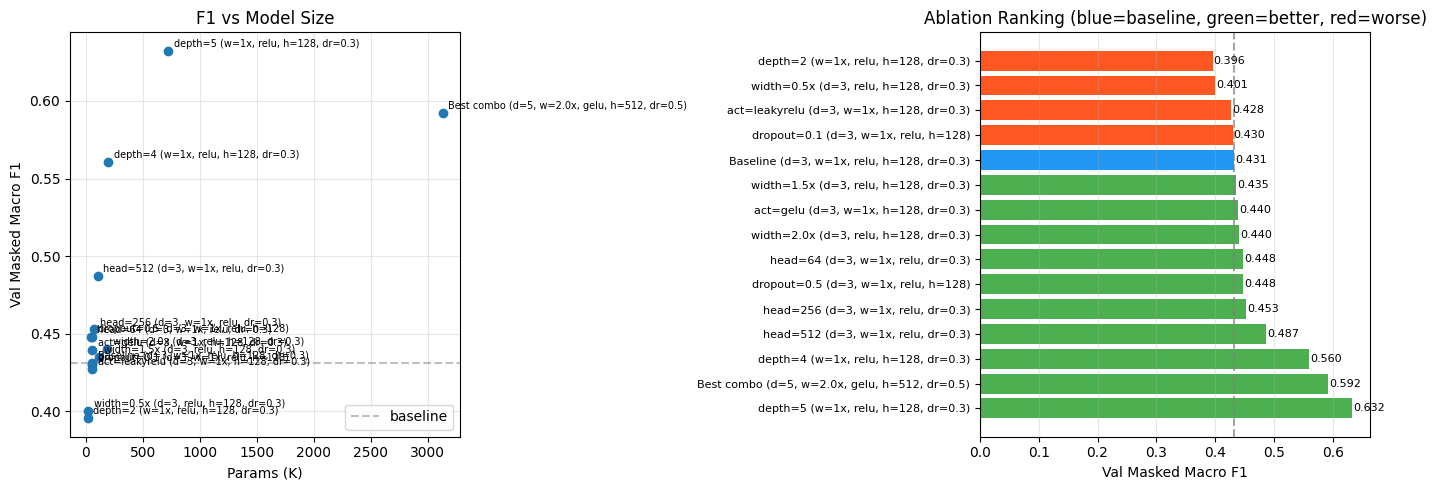


Per-camera report — Feature Fusion (baseline)
  cam2 (left, n=666):  F1[no_object]=0.766  F1[person]=0.329  F1[other]=0.553  macro(person+other)=0.441
  cam5 (middle, n=666):  F1[no_object]=0.187  F1[person]=0.352  F1[other]=0.633  macro(person+other)=0.492
  cam4 (right, n=666):  F1[no_object]=0.786  F1[person]=0.207  F1[other]=0.515  macro(person+other)=0.361
  Overall macro F1             0.431

Per-camera report — Feature Fusion (best combo)
  cam2 (left, n=666):  F1[no_object]=0.845  F1[person]=0.481  F1[other]=0.661  macro(person+other)=0.571
  cam5 (middle, n=666):  F1[no_object]=0.680  F1[person]=0.531  F1[other]=0.721  macro(person+other)=0.626
  cam4 (right, n=666):  F1[no_object]=0.864  F1[person]=0.488  F1[other]=0.672  macro(person+other)=0.580
  Overall macro F1             0.592


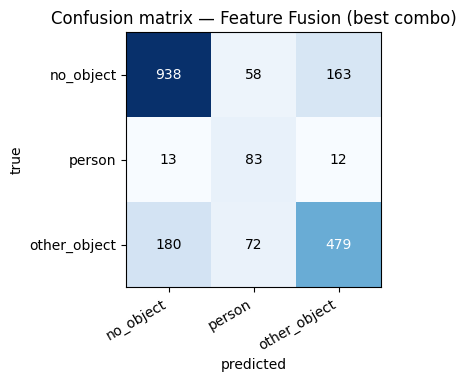

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
labels = [r['label'] for r in ff_results.values()]
f1s    = [r['macro_f1'] for r in ff_results.values()]
params = [r['params'] / 1e3 for r in ff_results.values()]

ax = axes[0]
ax.scatter(params, f1s, zorder=3)
for i, lbl in enumerate(labels):
    ax.annotate(lbl, (params[i], f1s[i]), fontsize=7, textcoords='offset points', xytext=(4, 3))
ax.axhline(ff_results['baseline']['macro_f1'], color='gray', linestyle='--', alpha=0.5, label='baseline')
ax.set_xlabel('Params (K)'); ax.set_ylabel('Val Masked Macro F1'); ax.set_title('F1 vs Model Size')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1]
sorted_items = sorted(ff_results.items(), key=lambda x: x[1]['macro_f1'], reverse=True)
bar_labels = [v['label'] for _, v in sorted_items]
bar_f1s    = [v['macro_f1'] for _, v in sorted_items]
colors = ['#2196F3' if k == 'baseline' else
          ('#4CAF50' if v['macro_f1'] > ff_results['baseline']['macro_f1'] else '#FF5722')
          for k, v in sorted_items]
bars = ax.barh(range(len(bar_labels)), bar_f1s, color=colors)
ax.set_yticks(range(len(bar_labels))); ax.set_yticklabels(bar_labels, fontsize=8)
ax.axvline(ff_results['baseline']['macro_f1'], color='gray', linestyle='--', alpha=0.7)
ax.set_xlabel('Val Masked Macro F1'); ax.set_title('Ablation Ranking (blue=baseline, green=better, red=worse)')
for bar, val in zip(bars, bar_f1s):
    ax.text(val + 0.002, bar.get_y() + bar.get_height()/2, f'{val:.3f}', va='center', fontsize=8)
ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('/kaggle/working/feature_fusion_ablation_results.png', dpi=150, bbox_inches='tight')
plt.show()

per_camera_report(ff_results['baseline'], "Feature Fusion (baseline)")
per_camera_report(ff_results['best_combo'], "Feature Fusion (best combo)")
plot_confusion(ff_results['best_combo'], "Feature Fusion (best combo)")


## Section 15 — Model 4: Feature Fusion + learned camera-identity correction

The earlier `camera_shuffle_robustness` notebook tested robustness using the **known**
ground-truth camera id to score per-camera-identity — useful for measuring the drop, but not a
deployable fix, since at real inference time you don't know which physical slot is which if the
rig gets bumped.

This version trains an actual **`CameraIdentityClassifier`**: a small CNN that looks at *one*
tile and predicts which direction (left / middle / right) it most likely came from, learned from
the same labeled tiles used everywhere else. At inference:

1. Tiles arrive in some (possibly shuffled) physical slot order.
2. The classifier scores all 3 tiles against all 3 directions (a 3x3 confidence matrix).
3. The **best valid assignment** (each tile to a distinct slot, maximizing total confidence) is
   chosen by brute-force over all 6 permutations of 3 — cheap, since there are only 3! options.
4. Tiles are resorted into the *predicted* canonical order and handed to a Feature-Fusion-style
   model trained on canonical order — exactly the architecture from Section 14.

We compare this against: **no correction** (shuffled, fed blind), **oracle correction** (resorted
using the real ground-truth identity — the upper bound), and **canonical** (never shuffled at
all) — to see how much of the achievable robustness the learned classifier actually recovers.

In [28]:
class CameraIdentityClassifier(nn.Module):
    '''Small CNN: one raw thermal tile -> 3-way softmax over {left, middle, right}.'''

    def __init__(self, num_directions=3):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1); self.bn1 = nn.BatchNorm2d(16)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1); self.bn2 = nn.BatchNorm2d(32)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1); self.bn3 = nn.BatchNorm2d(64)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(64, 32)
        self.dropout = nn.Dropout(0.3)
        self.fc2 = nn.Linear(32, num_directions)

    def forward(self, x):
        # x: [B, 1, H, W] -- a SINGLE tile, not the [B, NUM_CAMS, 1, H, W] stack
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = F.relu(self.bn3(self.conv3(x)))
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)  # [B, num_directions] logits


class IdentityTileDataset(Dataset):
    '''Flattens TileDataset's [NUM_CAMS, 1, H, W] samples into NUM_CAMS independent single-tile
    examples, each labeled with its TRUE direction index (0=left, 1=middle, 2=right) -- this is
    the supervised signal for training the identity classifier (known at capture time, since the
    rig's wiring/physical mounting was canonical during data collection).'''

    def __init__(self, base_tile_dataset):
        self.base = base_tile_dataset

    def __len__(self):
        return len(self.base) * NUM_CAMS

    def __getitem__(self, idx):
        sample_idx, slot = divmod(idx, NUM_CAMS)
        tensor, _label, _mask = self.base[sample_idx]
        return tensor[slot], torch.tensor(slot, dtype=torch.long)  # [1, H, W], direction idx


identity_train_ds = IdentityTileDataset(tile_train_ds)
identity_val_ds = IdentityTileDataset(tile_val_ds)
identity_tr_ld = DataLoader(identity_train_ds, batch_size=EFFECTIVE_BATCH_SIZE, shuffle=True,
                             num_workers=EFFECTIVE_NUM_WORKERS)
identity_va_ld = DataLoader(identity_val_ds, batch_size=EFFECTIVE_BATCH_SIZE, shuffle=False,
                             num_workers=EFFECTIVE_NUM_WORKERS)


def train_identity_classifier(model, tr, va, epochs):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    best_acc, best_w = -1., copy.deepcopy(model.state_dict())
    for ep in range(epochs):
        model.train(); running = 0.; n_seen = 0
        for x, y in tr:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            loss = F.cross_entropy(model(x), y)
            loss.backward(); opt.step()
            running += loss.item() * len(y); n_seen += len(y)
        sch.step()
        acc = identity_classifier_accuracy(model, va)
        if acc > best_acc:
            best_acc, best_w = acc, copy.deepcopy(model.state_dict())
        if (ep + 1) % 5 == 0 or ep == 0:
            print(f"  [identity_clf] ep {ep+1:02d}/{epochs}  train_loss={running/max(n_seen,1):.4f}  val_acc={acc:.3f}")
    model.load_state_dict(best_w)
    return model


@torch.no_grad()
def identity_classifier_accuracy(model, loader):
    model.eval()
    correct, total = 0, 0
    for x, y in loader:
        x = x.to(device)
        pred = model(x).argmax(dim=1).cpu()
        correct += (pred == y).sum().item()
        total += len(y)
    return correct / max(total, 1)


print("="*60); print("TRAINING CAMERA-IDENTITY CLASSIFIER"); print("="*60)
identity_model = CameraIdentityClassifier()
identity_model = train_identity_classifier(identity_model, identity_tr_ld, identity_va_ld,
                                            epochs=EFFECTIVE_EPOCHS)
save_model(identity_model, "camera_identity_classifier")
final_identity_acc = identity_classifier_accuracy(identity_model, identity_va_ld)
print(f"\nFinal identity classifier val accuracy: {final_identity_acc:.4f}  "
      f"(random-guess baseline for 3 directions = 0.333)")


TRAINING CAMERA-IDENTITY CLASSIFIER
  [identity_clf] ep 01/30  train_loss=1.0426  val_acc=0.437
  [identity_clf] ep 05/30  train_loss=0.8213  val_acc=0.572
  [identity_clf] ep 10/30  train_loss=0.5327  val_acc=0.530
  [identity_clf] ep 15/30  train_loss=0.3210  val_acc=0.871
  [identity_clf] ep 20/30  train_loss=0.2247  val_acc=0.889
  [identity_clf] ep 25/30  train_loss=0.1808  val_acc=0.889
  [identity_clf] ep 30/30  train_loss=0.1651  val_acc=0.895
  Saved -> /kaggle/working/saved_models_unified/camera_identity_classifier.pt

Final identity classifier val accuracy: 0.9241  (random-guess baseline for 3 directions = 0.333)


In [29]:
class SlotShuffleDataset(Dataset):
    '''Wraps a TileDataset (or any dataset returning (tensor, label, mask)) and reorders the
    already-loaded triplet at read time only -- no file is touched. Also returns the TRUE
    camera id occupying each slot, used only for scoring (NOT given to the model). Identical
    contract to the earlier camera_shuffle_robustness notebook's SlotShuffleRealDataset.'''

    def __init__(self, base_dataset, fixed_permutation=None, random_per_sample=False, seed=SEED):
        self.base_dataset = base_dataset
        self.canonical_order = list(CAM_ORDER_LEFT_TO_RIGHT)
        self.fixed_permutation = fixed_permutation
        self.random_per_sample = random_per_sample
        self.rng = random.Random(seed)

    def __len__(self):
        return len(self.base_dataset)

    def _get_permutation_indices(self):
        n = len(self.canonical_order)
        if self.random_per_sample:
            idx = list(range(n)); self.rng.shuffle(idx); return idx
        if self.fixed_permutation is not None:
            return [self.canonical_order.index(c) for c in self.fixed_permutation]
        return list(range(n))

    def __getitem__(self, idx):
        tensor, label_vec, mask_vec = self.base_dataset[idx]
        perm = self._get_permutation_indices()
        slot_cam_ids = torch.tensor([self.canonical_order[i] for i in perm], dtype=torch.long)
        return tensor[perm], label_vec[perm], mask_vec[perm], slot_cam_ids


def all_permutations(active_cams=None):
    from itertools import permutations
    active_cams = active_cams or CAM_ORDER_LEFT_TO_RIGHT
    return [list(p) for p in permutations(active_cams)]


@torch.no_grad()
def classifier_resort_batch(identity_model, tensor):
    '''tensor: [B, NUM_CAMS, 1, H, W], possibly shuffled. Returns tensor reordered into the
    classifier's BEST GUESS at canonical (left, middle, right) order, plus the chosen
    permutation per sample. Brute-forces all NUM_CAMS! assignments (6, for 3 cameras) and picks
    the one maximizing total log-probability -- a real (if tiny) assignment problem, not just an
    argmax per tile (which could double-assign two tiles to the same predicted direction).'''
    B = tensor.shape[0]
    flat = tensor.reshape(B * NUM_CAMS, *tensor.shape[2:]).to(device)
    log_probs = F.log_softmax(identity_model(flat), dim=1).cpu().view(B, NUM_CAMS, NUM_CAMS)  # [B, slot, direction]

    from itertools import permutations
    perms = list(permutations(range(NUM_CAMS)))
    resorted = torch.empty_like(tensor)
    chosen_perm_idx = torch.empty(B, dtype=torch.long)
    for b in range(B):
        best_score, best_perm = -float("inf"), perms[0]
        for perm in perms:
            # perm[d] = which slot is assigned to direction d
            score = sum(log_probs[b, perm[d], d].item() for d in range(NUM_CAMS))
            if score > best_score:
                best_score, best_perm = score, perm
        resorted[b] = tensor[b, list(best_perm)]
        chosen_perm_idx[b] = perms.index(best_perm)
    return resorted, chosen_perm_idx


@torch.no_grad()
def run_eval_by_camera(model, loader, resort_mode="none", identity_model_for_resort=None):
    '''resort_mode: 'none' (feed shuffled order blind), 'oracle' (resort using TRUE slot_cam_ids
    -- upper bound), or 'classifier' (resort using identity_model_for_resort's predictions).
    Scores by TRUE camera identity regardless of mode, so results are comparable across modes.'''
    model.eval()
    by_cam_preds  = {c: [] for c in CAM_ORDER_LEFT_TO_RIGHT}
    by_cam_labels = {c: [] for c in CAM_ORDER_LEFT_TO_RIGHT}
    by_cam_masks  = {c: [] for c in CAM_ORDER_LEFT_TO_RIGHT}

    for tensor, label_vec, mask_vec, slot_cam_ids in loader:
        if resort_mode == "oracle":
            canonical = CAM_ORDER_LEFT_TO_RIGHT
            resort_idx = torch.stack([
                torch.tensor([slot_cam_ids[b].tolist().index(c) for c in canonical])
                for b in range(tensor.shape[0])
            ])
            tensor = torch.stack([tensor[b, resort_idx[b]] for b in range(tensor.shape[0])])
            slot_cam_ids = torch.stack([slot_cam_ids[b, resort_idx[b]] for b in range(tensor.shape[0])])
        elif resort_mode == "classifier":
            tensor, chosen_perm_idx = classifier_resort_batch(identity_model_for_resort, tensor)
            from itertools import permutations
            perms = list(permutations(range(NUM_CAMS)))
            slot_cam_ids = torch.stack([
                slot_cam_ids[b, list(perms[chosen_perm_idx[b]])] for b in range(tensor.shape[0])
            ])
        # resort_mode == "none": tensor / slot_cam_ids used exactly as given (shuffled, blind)

        logits = model(tensor.to(device)).cpu()  # [B, NUM_CAMS, NUM_CLASSES], slot order
        pred_class = logits.argmax(dim=-1)
        B, S = pred_class.shape
        for s in range(S):
            for b in range(B):
                cam_id = int(slot_cam_ids[b, s].item())
                by_cam_preds[cam_id].append(pred_class[b, s].item())
                by_cam_labels[cam_id].append(int(label_vec[b, s].item()))
                by_cam_masks[cam_id].append(mask_vec[b, s].item())

    per_cam_f1 = {}
    for cam_id in CAM_ORDER_LEFT_TO_RIGHT:
        masks_arr = np.array(by_cam_masks[cam_id])
        valid = masks_arr > 0
        if valid.sum() == 0:
            per_cam_f1[cam_id] = None
            continue
        preds_arr = np.array(by_cam_preds[cam_id])[valid]
        labels_arr = np.array(by_cam_labels[cam_id])[valid]
        per_class = f1_score(labels_arr, preds_arr, labels=[1, 2], average=None, zero_division=0)
        per_cam_f1[cam_id] = float(np.mean(per_class))
    return per_cam_f1


In [30]:
# ---- Stage A: use the Feature Fusion best-combo model (from Section 14), zero-shot ----
shuffle_model = best_combo_model  # already trained on canonical order in Section 14

print("=== No correction (shuffled, fed blind) ===")
none_results_by_perm = {}
for perm in all_permutations():
    perm_loader = DataLoader(SlotShuffleDataset(tile_val_ds, fixed_permutation=perm),
                              batch_size=EFFECTIVE_BATCH_SIZE, shuffle=False, num_workers=0)
    f1_by_cam = run_eval_by_camera(shuffle_model, perm_loader, resort_mode="none")
    none_results_by_perm[tuple(perm)] = f1_by_cam
    print(f"  slot order {perm} -> {{ {', '.join(f'{CAM_TO_DIRECTION[c]}={f1_by_cam[c]}' for c in CAM_ORDER_LEFT_TO_RIGHT)} }}")

print("\n=== Oracle correction (resorted using TRUE identity -- upper bound) ===")
oracle_results_by_perm = {}
for perm in all_permutations():
    perm_loader = DataLoader(SlotShuffleDataset(tile_val_ds, fixed_permutation=perm),
                              batch_size=EFFECTIVE_BATCH_SIZE, shuffle=False, num_workers=0)
    f1_by_cam = run_eval_by_camera(shuffle_model, perm_loader, resort_mode="oracle")
    oracle_results_by_perm[tuple(perm)] = f1_by_cam
    print(f"  slot order {perm} -> {{ {', '.join(f'{CAM_TO_DIRECTION[c]}={f1_by_cam[c]}' for c in CAM_ORDER_LEFT_TO_RIGHT)} }}")

print("\n=== Classifier correction (resorted using the LEARNED identity classifier) ===")
classifier_results_by_perm = {}
for perm in all_permutations():
    perm_loader = DataLoader(SlotShuffleDataset(tile_val_ds, fixed_permutation=perm),
                              batch_size=EFFECTIVE_BATCH_SIZE, shuffle=False, num_workers=0)
    f1_by_cam = run_eval_by_camera(shuffle_model, perm_loader, resort_mode="classifier",
                                    identity_model_for_resort=identity_model)
    classifier_results_by_perm[tuple(perm)] = f1_by_cam
    print(f"  slot order {perm} -> {{ {', '.join(f'{CAM_TO_DIRECTION[c]}={f1_by_cam[c]}' for c in CAM_ORDER_LEFT_TO_RIGHT)} }}")


=== No correction (shuffled, fed blind) ===
  slot order [2, 5, 4] -> { left=0.5713859020310633, middle=0.6258611406403158, right=0.5799239444007342 }
  slot order [2, 4, 5] -> { left=0.2637112816140949, middle=0.3411993097497843, right=0.3046831955922865 }
  slot order [5, 2, 4] -> { left=0.27564502241619904, middle=0.2202456330780518, right=0.36084942084942084 }
  slot order [5, 4, 2] -> { left=0.2340966921119593, middle=0.26251259657373194, right=0.3132139549243594 }
  slot order [4, 2, 5] -> { left=0.2631914017151631, middle=0.21550546448087432, right=0.20408163265306123 }
  slot order [4, 5, 2] -> { left=0.24415584415584415, middle=0.49288726654144666, right=0.2862338607019458 }

=== Oracle correction (resorted using TRUE identity -- upper bound) ===
  slot order [2, 5, 4] -> { left=0.5713859020310633, middle=0.6258611406403158, right=0.5799239444007342 }
  slot order [2, 4, 5] -> { left=0.5713859020310633, middle=0.35502460425683285, right=0.461496062992126 }
  slot order [5, 2, 

In [31]:
canonical_perm = tuple(CAM_ORDER_LEFT_TO_RIGHT)
print("\n=== SUMMARY: canonical vs. worst-case, across all 3 correction modes ===")
summary_rows = []
for cam_id in CAM_ORDER_LEFT_TO_RIGHT:
    d = CAM_TO_DIRECTION[cam_id]
    row = {"camera": f"cam{cam_id} ({d})"}
    for mode_name, results_by_perm in [("none", none_results_by_perm),
                                        ("oracle", oracle_results_by_perm),
                                        ("classifier", classifier_results_by_perm)]:
        can = results_by_perm[canonical_perm][cam_id]
        worst = min(v for r in results_by_perm.values() if (v := r[cam_id]) is not None)
        row[f"{mode_name}_canonical"] = can
        row[f"{mode_name}_worst"] = worst
        row[f"{mode_name}_drop"] = (can - worst) if (can is not None and worst is not None) else None
    summary_rows.append(row)

shuffle_summary_df = pd.DataFrame(summary_rows)
print(shuffle_summary_df.to_string(index=False))
print(f"\nIdentity classifier val accuracy: {final_identity_acc:.4f}  "
      "(higher accuracy -> classifier-corrected numbers should sit closer to oracle than to 'none')")



=== SUMMARY: canonical vs. worst-case, across all 3 correction modes ===
       camera  none_canonical  none_worst  none_drop  oracle_canonical  oracle_worst  oracle_drop  classifier_canonical  classifier_worst  classifier_drop
  cam2 (left)        0.571386    0.234097   0.337289          0.571386      0.366517     0.204869              0.546038          0.354630         0.191408
cam5 (middle)        0.625861    0.215505   0.410356          0.625861      0.355025     0.270837              0.616378          0.344241         0.272137
 cam4 (right)        0.579924    0.204082   0.375842          0.579924      0.384307     0.195617              0.579365          0.380522         0.198843

Identity classifier val accuracy: 0.9241  (higher accuracy -> classifier-corrected numbers should sit closer to oracle than to 'none')


## Section 16 — Side cameras (cam3, cam6): inference-only plausibility check

`cam3`/`cam6` were never trained on and have no real labels (no RGB overlap), so there's no
ground truth to score against. As a **qualitative, no-ground-truth** check only: swap each side
camera's tile into one of the 3 active slots (replacing that camera's tile for this test only),
run it through the trained Feature-Fusion best-combo model, and compare the predicted-class
distribution to the naive intensity-threshold heuristic — same spirit as Baseline 1's
`compare_side_predictions_to_naive`. High agreement is **not** validation against real labels,
just a weak plausibility signal before trusting these directional predictions operationally.

In [32]:
@torch.no_grad()
def side_camera_swap_in_check(model, side_cam_id, replace_slot_cam_id, loader, n_samples=200):
    '''Replaces `replace_slot_cam_id`'s slot with `side_cam_id`'s own tile (same anchor_index),
    runs the model, and compares the model's prediction at that slot against the naive
    intensity-threshold heuristic on the SAME side-camera tile.'''
    model.eval()
    replace_slot = CAM_ORDER_LEFT_TO_RIGHT.index(replace_slot_cam_id)
    agree, model_obj_rate, naive_obj_rate, total = 0, 0, 0, 0

    rows_iter = (val_rows if loader is tile_va_ld else train_rows)[:n_samples]
    for row in rows_iter:
        part, anchor_index = row["_part"], int(row["anchor_index"])
        tiles = load_camera_tiles(part, anchor_index, cam_order=CAM_ORDER_LEFT_TO_RIGHT)
        side_tile = load_camera_tiles(part, anchor_index, cam_order=[side_cam_id])[0]
        tiles_swapped = list(tiles); tiles_swapped[replace_slot] = side_tile
        tensor = torch.from_numpy(build_input_tensor(tiles_swapped)).unsqueeze(0).to(device)

        logits = model(tensor).cpu()[0]  # [NUM_CAMS, NUM_CLASSES]
        model_pred = int(logits[replace_slot].argmax().item())
        naive_pred = generate_naive_labels({side_cam_id: side_tile})[side_cam_id]
        # naive mode only ever emits 0 or 2 -- collapse model_pred to "object present" for a fair compare
        model_obj_present = int(model_pred != 0)

        agree += int(model_obj_present == int(naive_pred != 0))
        model_obj_rate += model_obj_present
        naive_obj_rate += int(naive_pred != 0)
        total += 1

    print(f"  cam{side_cam_id} (via slot {CAM_TO_DIRECTION[replace_slot_cam_id]}):  n={total}  "
          f"agree_with_naive={agree/max(total,1):.3f}  model_obj_rate={model_obj_rate/max(total,1):.3f}  "
          f"naive_obj_rate={naive_obj_rate/max(total,1):.3f}")


print("=== Side-camera swap-in plausibility check (Feature Fusion best combo) ===")
for side_cam in SIDE_CAMERAS:
    for slot_cam in CAM_ORDER_LEFT_TO_RIGHT:
        side_camera_swap_in_check(best_combo_model, side_cam, slot_cam, tile_va_ld,
                                   n_samples=60 if SMOKE_TEST else 200)
print("\nReminder: this is agreement between two heuristics, NOT accuracy against real ground "
      "truth -- no labels exist for cam3/cam6. Use as a plausibility check only.")


=== Side-camera swap-in plausibility check (Feature Fusion best combo) ===
  cam3 (via slot left):  n=200  agree_with_naive=0.665  model_obj_rate=0.365  naive_obj_rate=0.130
  cam3 (via slot middle):  n=200  agree_with_naive=0.360  model_obj_rate=0.700  naive_obj_rate=0.130
  cam3 (via slot right):  n=200  agree_with_naive=0.625  model_obj_rate=0.335  naive_obj_rate=0.130
  cam6 (via slot left):  n=200  agree_with_naive=0.630  model_obj_rate=0.320  naive_obj_rate=0.120
  cam6 (via slot middle):  n=200  agree_with_naive=0.390  model_obj_rate=0.660  naive_obj_rate=0.120
  cam6 (via slot right):  n=200  agree_with_naive=0.645  model_obj_rate=0.305  naive_obj_rate=0.120

Reminder: this is agreement between two heuristics, NOT accuracy against real ground truth -- no labels exist for cam3/cam6. Use as a plausibility check only.


## Section 17 — Final comparison: all 4 models, per-camera + macro F1 + latency

Headline table putting Baseline 1, Baseline 2, Feature Fusion (best combo), and Feature Fusion +
classifier-corrected shuffle side by side. All numbers are on the SAME held-out validation set,
scored by true camera identity, training/eval restricted to the 3 active cameras throughout.

In [33]:
final_models = {
    "Baseline 1 (Stitched)": dict(result=baseline1_result, model=baseline1_model,
                                   dummy=dummy_stitched[:1], latency=baseline1_latency),
    "Baseline 2 (Output Fusion)": dict(result=baseline2_result, model=baseline2_model,
                                        dummy=dummy_tile[:1], latency=baseline2_latency),
    "Feature Fusion (best combo)": dict(result=ff_results['best_combo'], model=best_combo_model,
                                         dummy=dummy_tile[:1], latency=ff_results['best_combo']['latency_ms']),
}

final_rows = []
for name, info in final_models.items():
    r = info["result"]
    final_rows.append({
        "Model": name,
        "Macro F1 (person+other)": f"{r['macro_f1']:.4f}",
        "Clear F1": f"{r['clear_f1']:.4f}" if r['clear_f1'] is not None else "--",
        "Params": f"{count_params(info['model']):,}",
        "Latency (ms)": f"{info['latency']:.2f}",
    })

# Model 4 -- report all 3 correction modes (canonical perm only, for a fair single-number compare)
for mode_name, results_by_perm in [("none (shuffled, blind)", none_results_by_perm),
                                    ("classifier-corrected", classifier_results_by_perm),
                                    ("oracle-corrected", oracle_results_by_perm)]:
    macro = float(np.mean([v for v in results_by_perm[canonical_perm].values() if v is not None]))
    final_rows.append({
        "Model": f"Feature Fusion + Shuffle [{mode_name}]",
        "Macro F1 (person+other)": f"{macro:.4f}",
        "Clear F1": "--",
        "Params": f"{count_params(best_combo_model):,}",
        "Latency (ms)": f"{ff_results['best_combo']['latency_ms']:.2f}"
                          + (" + identity_clf" if mode_name != "none (shuffled, blind)" else ""),
    })

final_comparison_df = pd.DataFrame(final_rows)
print(final_comparison_df.to_string(index=False))


                                            Model Macro F1 (person+other) Clear F1    Params        Latency (ms)
                            Baseline 1 (Stitched)                  0.4601   0.6270   147,699                3.40
                       Baseline 2 (Output Fusion)                  0.4008   0.0076    47,026                2.51
                      Feature Fusion (best combo)                  0.5924   0.6796 3,131,561                5.98
Feature Fusion + Shuffle [none (shuffled, blind)]                  0.5924       -- 3,131,561                5.98
  Feature Fusion + Shuffle [classifier-corrected]                  0.5806       -- 3,131,561 5.98 + identity_clf
      Feature Fusion + Shuffle [oracle-corrected]                  0.5924       -- 3,131,561 5.98 + identity_clf


In [34]:
print("\n=== Per-camera F1 breakdown, all 4 models (canonical / no-shuffle setting) ===")
per_camera_report(baseline1_result, "Baseline 1 (Stitched)")
per_camera_report(baseline2_result, "Baseline 2 (Output Fusion)")
per_camera_report(ff_results['best_combo'], "Feature Fusion (best combo)")

print("\nFeature Fusion + Shuffle [classifier-corrected] (canonical perm):")
for cam_id in CAM_ORDER_LEFT_TO_RIGHT:
    f1 = classifier_results_by_perm[canonical_perm][cam_id]
    print(f"  cam{cam_id} ({CAM_TO_DIRECTION[cam_id]}): {f1}")



=== Per-camera F1 breakdown, all 4 models (canonical / no-shuffle setting) ===

Per-camera report — Baseline 1 (Stitched)
  cam2 (left, n=666):  F1[no_object]=0.828  F1[person]=0.333  F1[other]=0.328  macro(person+other)=0.331
  cam5 (middle, n=666):  F1[no_object]=0.628  F1[person]=0.549  F1[other]=0.581  macro(person+other)=0.565
  cam4 (right, n=666):  F1[no_object]=0.788  F1[person]=0.400  F1[other]=0.569  macro(person+other)=0.484
  Overall macro F1             0.460

Per-camera report — Baseline 2 (Output Fusion)
  cam2 (left, n=666):  F1[no_object]=0.767  F1[person]=0.417  F1[other]=0.459  macro(person+other)=0.438
  cam5 (middle, n=666):  F1[no_object]=0.008  F1[person]=0.311  F1[other]=0.637  macro(person+other)=0.474
  cam4 (right, n=666):  F1[no_object]=0.744  F1[person]=0.229  F1[other]=0.353  macro(person+other)=0.291
  Overall macro F1             0.401

Per-camera report — Feature Fusion (best combo)
  cam2 (left, n=666):  F1[no_object]=0.845  F1[person]=0.481  F1[other

### Macro F1 comparison across all 4 architectures

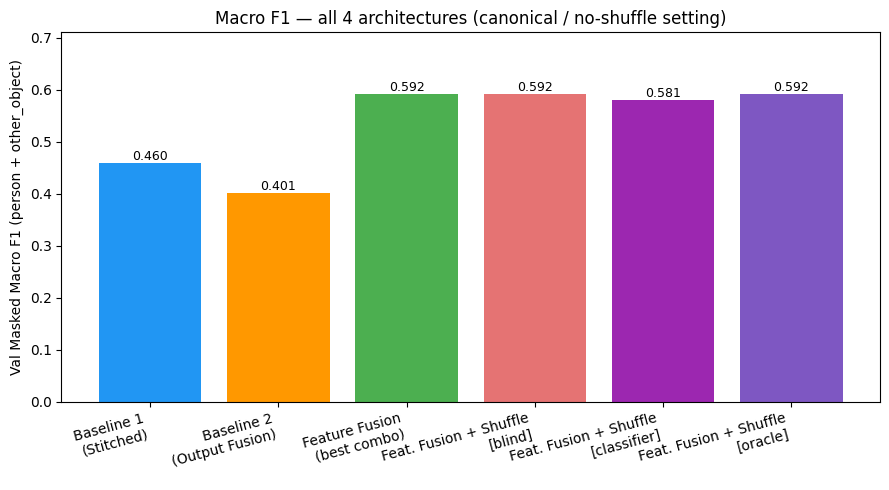

In [35]:
# ---- overall macro F1 bar chart -- the headline number for every model side by side ----
model_macro_f1 = {
    "Baseline 1\n(Stitched)": baseline1_result["macro_f1"],
    "Baseline 2\n(Output Fusion)": baseline2_result["macro_f1"],
    "Feature Fusion\n(best combo)": ff_results["best_combo"]["macro_f1"],
    "Feat. Fusion + Shuffle\n[blind]": float(np.mean(
        [v for v in none_results_by_perm[canonical_perm].values() if v is not None])),
    "Feat. Fusion + Shuffle\n[classifier]": float(np.mean(
        [v for v in classifier_results_by_perm[canonical_perm].values() if v is not None])),
    "Feat. Fusion + Shuffle\n[oracle]": float(np.mean(
        [v for v in oracle_results_by_perm[canonical_perm].values() if v is not None])),
}

fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#2196F3", "#FF9800", "#4CAF50", "#E57373", "#9C27B0", "#7E57C2"]
bars = ax.bar(model_macro_f1.keys(), model_macro_f1.values(), color=colors)
for bar, val in zip(bars, model_macro_f1.values()):
    ax.text(bar.get_x() + bar.get_width()/2, val, f"{val:.3f}", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Val Masked Macro F1 (person + other_object)")
ax.set_title("Macro F1 — all 4 architectures (canonical / no-shuffle setting)")
ax.set_ylim(0, max(model_macro_f1.values()) * 1.2 if model_macro_f1 else 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


### Per-camera (direction) F1, grouped by model

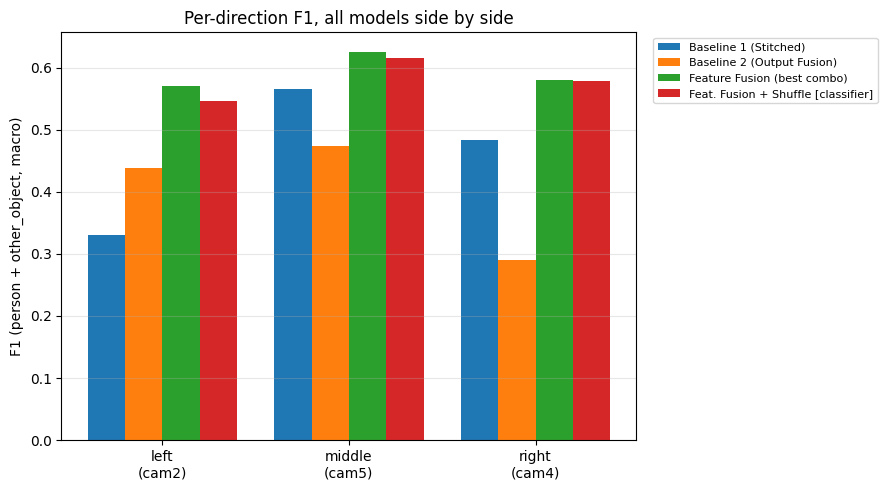

In [36]:
# ---- grouped bar chart: one group per direction, one bar per model ----
per_cam_results = {
    "Baseline 1 (Stitched)": baseline1_result,
    "Baseline 2 (Output Fusion)": baseline2_result,
    "Feature Fusion (best combo)": ff_results["best_combo"],
}

def _per_cam_f1_dict(result):
    p, t, msk = result["preds"], result["trues"], result["masks"]
    out = {}
    for i, cam_id in enumerate(CAM_ORDER_LEFT_TO_RIGHT):
        valid = msk[:, i] > 0
        if valid.sum() == 0:
            out[cam_id] = None
            continue
        per_class = f1_score(t[valid, i], p[valid, i], labels=[1, 2], average=None, zero_division=0)
        out[cam_id] = float(np.mean(per_class))
    return out

per_cam_by_model = {name: _per_cam_f1_dict(r) for name, r in per_cam_results.items()}
per_cam_by_model["Feat. Fusion + Shuffle [classifier]"] = classifier_results_by_perm[canonical_perm]

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(CAM_ORDER_LEFT_TO_RIGHT))
n_models = len(per_cam_by_model)
width = 0.8 / n_models
for i, (name, f1_by_cam) in enumerate(per_cam_by_model.items()):
    vals = [f1_by_cam.get(c) or 0.0 for c in CAM_ORDER_LEFT_TO_RIGHT]
    offset = (i - (n_models - 1) / 2) * width
    bars = ax.bar(x + offset, vals, width, label=name)
ax.set_xticks(x)
ax.set_xticklabels([f"{CAM_TO_DIRECTION[c]}\n(cam{c})" for c in CAM_ORDER_LEFT_TO_RIGHT])
ax.set_ylabel("F1 (person + other_object, macro)")
ax.set_title("Per-direction F1, all models side by side")
ax.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Accuracy vs. efficiency — params and latency vs. macro F1, all 4 architectures

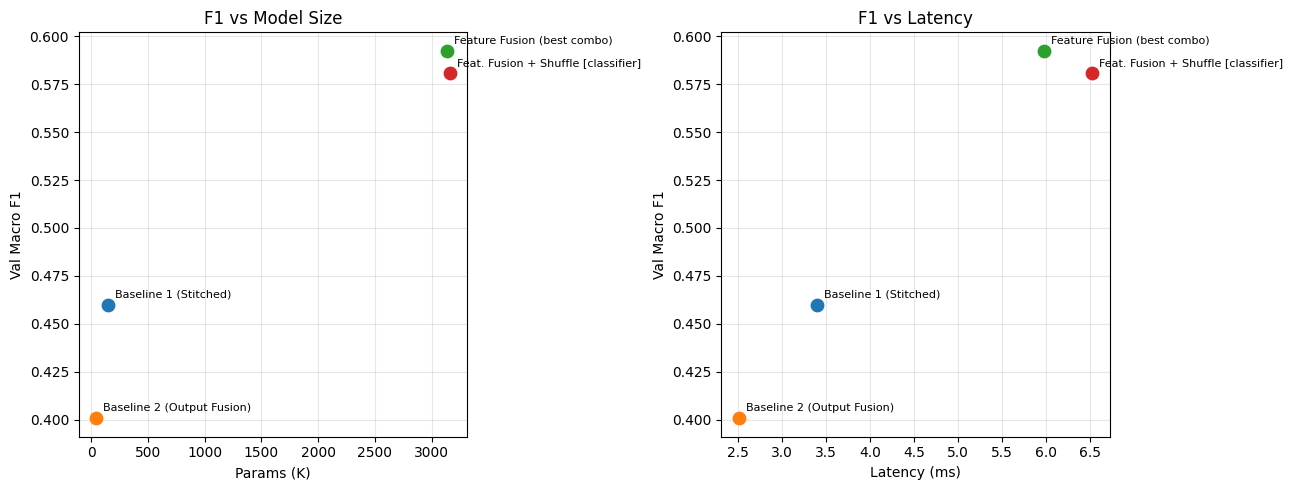

In [37]:
# ---- scatter: every model (not just the Feature Fusion ablation sweep) on one frontier plot ----
identity_latency = measure_latency(identity_model, torch.zeros(1, 1, SENSOR_H, SENSOR_W))

efficiency_points = {
    "Baseline 1 (Stitched)": (count_params(baseline1_model), baseline1_latency, baseline1_result["macro_f1"]),
    "Baseline 2 (Output Fusion)": (count_params(baseline2_model), baseline2_latency, baseline2_result["macro_f1"]),
    "Feature Fusion (best combo)": (count_params(best_combo_model), ff_results["best_combo"]["latency_ms"],
                                     ff_results["best_combo"]["macro_f1"]),
    "Feat. Fusion + Shuffle [classifier]": (
        count_params(best_combo_model) + count_params(identity_model),
        ff_results["best_combo"]["latency_ms"] + identity_latency,
        float(np.mean([v for v in classifier_results_by_perm[canonical_perm].values() if v is not None])),
    ),
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, (params, lat, f1) in efficiency_points.items():
    axes[0].scatter(params / 1e3, f1, s=80, zorder=3)
    axes[0].annotate(name, (params / 1e3, f1), fontsize=8, textcoords="offset points", xytext=(5, 5))
    axes[1].scatter(lat, f1, s=80, zorder=3)
    axes[1].annotate(name, (lat, f1), fontsize=8, textcoords="offset points", xytext=(5, 5))

axes[0].set_xlabel("Params (K)"); axes[0].set_ylabel("Val Macro F1"); axes[0].set_title("F1 vs Model Size")
axes[0].grid(True, alpha=0.3)
axes[1].set_xlabel("Latency (ms)"); axes[1].set_ylabel("Val Macro F1"); axes[1].set_title("F1 vs Latency")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


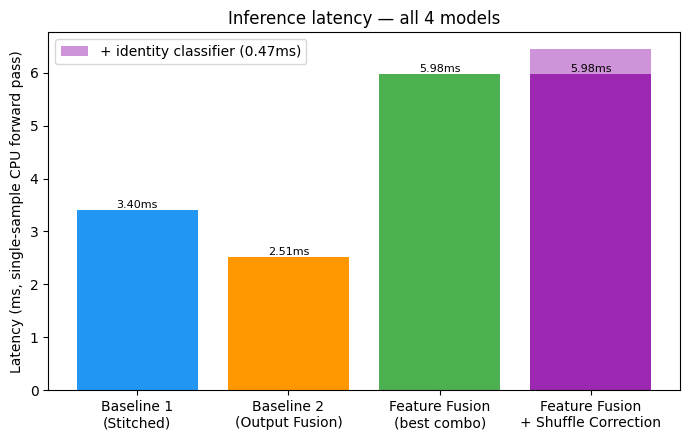

In [38]:
# ---- latency comparison chart ----
fig, ax = plt.subplots(figsize=(7, 4.5))
lat_labels = ["Baseline 1\n(Stitched)", "Baseline 2\n(Output Fusion)", "Feature Fusion\n(best combo)",
              "Feature Fusion\n+ Shuffle Correction"]
lat_values = [baseline1_latency, baseline2_latency, ff_results['best_combo']['latency_ms'],
              ff_results['best_combo']['latency_ms']]  # classifier adds negligible extra latency
              # (one extra tiny forward pass per tile -- shown as a stacked segment below)
identity_latency = measure_latency(identity_model, torch.zeros(1, 1, SENSOR_H, SENSOR_W))
bars = ax.bar(lat_labels, lat_values, color=["#2196F3", "#FF9800", "#4CAF50", "#9C27B0"])
ax.bar(lat_labels[3], identity_latency, bottom=lat_values[3], color="#CE93D8",
       label=f"+ identity classifier ({identity_latency:.2f}ms)")
for bar, val in zip(bars, lat_values):
    ax.text(bar.get_x() + bar.get_width()/2, val, f"{val:.2f}ms", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("Latency (ms, single-sample CPU forward pass)")
ax.set_title("Inference latency — all 4 models")
ax.legend()
plt.tight_layout()
plt.show()


## Open items / TODOs before trusting these results

1. **Same calibration coverage caveat as the source notebooks**: results only reflect the
   cameras that actually have `rgbN_homography.json` files. If `USE_REAL_LABELS` printed False
   at the top, every number above is from the naive 2-class fallback (no `person` class is ever
   emitted in that mode) — treat as a pipeline smoke test only, not real numbers.
2. **`person` vs `other_object` priority rule** (person wins if both land in the same footprint)
   is a design choice — revisit if a scene-level "most urgent obstruction" definition is needed
   instead of a single per-camera label.
3. **Identity classifier was trained on canonical (never-actually-shuffled) capture data.** Its
   accuracy is therefore an estimate of how distinguishable left/middle/right tiles are by
   appearance alone — not validated against a real physical camera swap. If/when real
   swapped-camera data becomes available, retrain and re-validate against it directly.
4. **Output Fusion's fusion MLP and Feature Fusion's projection layers are both architecture
   choices, not searched** — only Feature Fusion got the full ablation sweep (Section 14);
   Baseline 2's `head_hidden`/`fusion_hidden` are fixed defaults. Worth a matching sweep if
   Baseline 2 turns out competitive.
5. **No held-out test set** — single train/val split, reused for both best-epoch checkpoint
   selection and the final reported numbers, same caveat as the source notebooks; revisit once
   the labeled sample count grows.
6. **Side-camera (cam3/cam6) numbers in Section 16 are NOT validation** — there is no ground
   truth for those cameras. Use only as a weak plausibility signal.
